# 🎓 KNOWLEDGE DISTILLATION — Ensemble Teacher ➜ Student nhẹ, logit-KD & ReKD (Task A & B)

Notebook thực hiện các khâu **Ensemble Teacher → Knowledge Distillation → Student nhẹ** trong sơ đồ pipeline, gồm cả **logit-KD** và **ReKD** (Relaxed Knowledge Distillation, Qu et al., IJCV 2026 — *bản tái hiện theo mô tả paper, không phải code chính thức*).
Dùng chung cho cả 2 task: đổi biến `TASK` ở cell đầu.

### Các biến thể huấn luyện (ablation)
| Biến thể | Loss | Teacher dùng |
|---|---|---|
| `baseline` | CE | — |
| `kd` | CE + logit-KD | **Ensemble** (trung bình logits của top-k teacher) |
| `kd_ord` *(chỉ Task B)* | CE ordinal-soft + logit-KD | Ensemble |
| `rekd` | CE + **ReKD** (đúng như paper: không có logit-KD) | **1 single teacher** (lấy feature) |
| `kd_rekd` | CE + logit-KD + ReKD | Ensemble (logits) + 1 single teacher (feature) |

ReKD là phương pháp *feature-based* nên cần feature map của **một** model; ensemble trung bình logits không có feature chung → teacher đơn do `FEATURE_TEACHER_KEY` chỉ định (mặc định: teacher có VAL Macro-F1 cao nhất).

### Quy ước tên run (mới)
`{student}__{variant}__{tag}__s{seed}`, trong đó `tag` mã hóa **tập teacher** (vd. `L-sw-vt__F-sw` = logit-teacher {swin, vit}, feature-teacher swin; `baseline` không có tag).
→ đổi tập teacher sẽ tạo run **mới**, không ghi đè / không bị bỏ qua nhầm. Tên teacher đầy đủ nằm trong `config.json`.
*(Mã viết tắt cố ý không chứa chữ `vit/swin/convnext/resnet` để Grad-CAM trong Evaluation không nhận nhầm kiến trúc.)*

### Thiết kế chung
| Vấn đề | Quyết định |
|---|---|
| Student | Mặc định **MobileNetV3-large** (EfficientNet-Lite0 còn trong `STUDENT_CONFIGS` nhưng baseline Task B ≈ 0.75, learning curve đã phẳng) |
| Teacher (logit) | Top-k theo **VAL Macro-F1** (không dùng test) — hoặc chỉ định tay bằng `LOGIT_TEACHER_KEYS` |
| Dữ liệu | Dùng lại **đúng** `taskA_split.json` / `taskB_split.json`; test không đụng tới |
| Augmentation | Đúng thứ tự **Resize → augment → Normalize**; tham số augment bốc 1 lần, áp giống nhau cho mọi view |
| Fine-tuning | 2-Stage (head-only → full fine-tune), early stopping theo val Macro-F1 |
| Seed | `SEEDS` nhiều giá trị; bảng cuối notebook so sánh **theo từng seed** với baseline |
| Idempotent | Run đã có `best_model.pth` thì bỏ qua (trừ khi `FORCE_RERUN=True`) |

### Loss
```
logit-KD :  L = (1-λ)·CE(y) + λ·T²·KL( softmax(t/T) ‖ softmax(s/T) )      (kd_ord: CE → CE với ordinal soft label)
ReKD     :  + L_NLL + α·L_PR + β·L_KD(ReKD)        (VAE trên feature teacher + mutual learning, xem mục 9)
```

### Output (Drive)
`outputs/Distill/Task{A|B}/{run}/` gồm `best_model.pth`, `config.json`, `history.csv`, learning curves, confusion matrix (val)… — **cùng định dạng** với notebook train nên `Evaluation.ipynb` đọc được.

⚠️ Notebook **CHỈ dùng train + val**. Test chỉ dùng trong `Evaluation.ipynb`.


## 0. Chọn task


In [ ]:
TASK = "A"   # "A" = Binary (Sperm vs Non-sperm)  |  "B" = Halo (đa lớp)
assert TASK in ("A", "B")
print("TASK =", TASK)


TASK = A


## 1. Cài đặt thư viện


In [ ]:
!pip install -q timm==1.0.11 scikit-learn seaborn


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.4/48.4 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 37.1 MB/s eta 0:00:00


## 2. Import & thiết lập seed / device


In [ ]:
import os, sys, json, time, random, shutil, zipfile, glob, copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import timm
from timm.data import resolve_data_config
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                              recall_score, confusion_matrix, classification_report)

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Thiết bị đang sử dụng: {device}")
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
import re
import torch.nn.functional as F


Thiết bị đang sử dụng: cuda
GPU: Tesla T4


## 3. Kết nối Google Drive & định nghĩa đường dẫn


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

DRIVE_ROOT       = "/content/drive/MyDrive/SpermAI_Benchmark"
DATA_DRIVE_DIR   = f"{DRIVE_ROOT}/data"                          # cache zip gốc + file chia tập cố định
TEACHER_DIR      = f"{DRIVE_ROOT}/outputs/Task{TASK}"            # nơi notebook train đã lưu các teacher (best_model.pth + config.json)
OUTPUT_DRIVE_DIR = f"{DRIVE_ROOT}/outputs/Distill/Task{TASK}"    # nơi notebook NÀY lưu student
os.makedirs(DATA_DRIVE_DIR, exist_ok=True)
os.makedirs(OUTPUT_DRIVE_DIR, exist_ok=True)

LOCAL_ROOT   = "/content/sperm_data"
RAW_ROOT     = f"{LOCAL_ROOT}/raw_extracted"
RAW_ZIP_PATH = f"{LOCAL_ROOT}/dataset_download.zip"
os.makedirs(LOCAL_ROOT, exist_ok=True)

print("TEACHER_DIR     :", TEACHER_DIR)
print("OUTPUT_DRIVE_DIR:", OUTPUT_DRIVE_DIR)


Mounted at /content/drive
TEACHER_DIR     : /content/drive/MyDrive/SpermAI_Benchmark/outputs/TaskA
OUTPUT_DRIVE_DIR: /content/drive/MyDrive/SpermAI_Benchmark/outputs/Distill/TaskA


## 4. Tải & giải nén dataset (idempotent — giống notebook train)


In [ ]:
import subprocess

FIGSHARE_ARTICLE_ID   = "30120811"
FIGSHARE_DOWNLOAD_URL = f"https://ndownloader.figshare.com/articles/{FIGSHARE_ARTICLE_ID}/versions/1"
DRIVE_CACHED_ZIP      = f"{DATA_DRIVE_DIR}/figshare_raw_dataset.zip"

def _find_dir(root, keyword):
    """Tìm (đệ quy) thư mục có tên chứa `keyword` (không phân biệt hoa/thường)."""
    keyword = keyword.lower()
    for dirpath, dirnames, _ in os.walk(root):
        for d in dirnames:
            if keyword in d.lower():
                return os.path.join(dirpath, d)
    return None

def _extract_recursive(zip_path, dest):
    """Giải nén archive Figshare bằng unrar.
    File Figshare có thể mang đuôi .zip nhưng thực tế chứa archive RAR
    (bên trong có Dataset/ và các thư mục dữ liệu thật)."""
    result = subprocess.run(
        ["unrar", "x", "-o+", "-p-", zip_path, dest + "/"],
        stdout=subprocess.DEVNULL,
        stderr=subprocess.PIPE,
        text=True
    )

    if result.returncode != 0:
        print(result.stderr)
        raise RuntimeError("Giải nén archive thất bại.")

def dataset_is_ready(root):
    """Dữ liệu thô được coi là sẵn sàng khi tìm thấy cả 2 thư mục nhãn gốc."""
    bin_dir  = _find_dir(root, "Binary Classification")
    halo_dir = _find_dir(root, "Halo Classification")
    ok = bool(bin_dir) and bool(halo_dir)
    if ok:
        print(f"  ✓ Tìm thấy: {bin_dir}")
        print(f"  ✓ Tìm thấy: {halo_dir}")
    return ok

if dataset_is_ready(RAW_ROOT):
    # ƯU TIÊN 1: dữ liệu đã có sẵn trong phần cứng Colab (phiên hiện tại) -> dùng chung, không tải lại
    print("✅ Dữ liệu thô đã có sẵn trong phần cứng Colab (phiên hiện tại) — bỏ qua tải & giải nén (dùng chung giữa các model).")
else:
    os.makedirs(RAW_ROOT, exist_ok=True)
    downloaded = False

    # ƯU TIÊN 2: đã có bản zip cache trên Google Drive (từ lần chạy trước, tự động HOẶC bạn tự upload thủ công)
    if os.path.exists(DRIVE_CACHED_ZIP):
        print("⬇️  Tìm thấy bản zip đã cache trên Google Drive → dùng bản này (KHÔNG tải lại từ Figshare).")
        shutil.copy(DRIVE_CACHED_ZIP, RAW_ZIP_PATH)
        downloaded = True
    else:
        # ƯU TIÊN 3 (chỉ xảy ra ở LẦN CHẠY ĐẦU TIÊN, khi Drive chưa có gì): tải từ Figshare
        print("⬇️  Chưa có bản cache trên Drive — đang tải dataset từ Figshare (chỉ xảy ra ở lần đầu tiên) ...")
        try:
            import urllib.request
            urllib.request.urlretrieve(FIGSHARE_DOWNLOAD_URL, RAW_ZIP_PATH)
            if os.path.getsize(RAW_ZIP_PATH) > 10_000:
                downloaded = True
        except Exception as e:
            print(f"  ✗ Tải từ Figshare thất bại: {e}")

    if not downloaded:
        raise RuntimeError(
            "Không thể tải dataset tự động (không có cache trên Drive, và tải từ Figshare thất bại).\n"
            "→ Hãy tải thủ công file zip tại https://doi.org/10.6084/m9.figshare.30120811,\n"
            f"  upload lên Google Drive đúng đường dẫn: {DRIVE_CACHED_ZIP}\n"
            "  rồi chạy lại cell này."
        )

    print("📦 Đang giải nén ...")
    _extract_recursive(RAW_ZIP_PATH, RAW_ROOT)

    if not dataset_is_ready(RAW_ROOT):
        raise RuntimeError(
            "Giải nén xong nhưng KHÔNG tìm thấy thư mục 'Binary Classification' hoặc 'Halo Classification'.\n"
            "→ Hãy kiểm tra thủ công cấu trúc bên trong RAW_ROOT (dùng lệnh !find) và chỉnh lại hàm _find_dir nếu tên khác."
        )

    # Nếu zip này vừa được tải MỚI từ Figshare (Drive lúc nãy chưa có) -> tự backup lên Drive cho các lần sau.
    # Nếu bạn muốn tự kiểm soát bản cache (tự nén thủ công), chỉ cần upload file của bạn đúng path
    # DRIVE_CACHED_ZIP trước khi chạy cell này — code sẽ ưu tiên dùng bản đó và bỏ qua bước tải Figshare.
    if not os.path.exists(DRIVE_CACHED_ZIP):
        print("☁️  Sao lưu zip gốc lên Drive để các lần chạy sau không cần tải lại từ Figshare ...")
        shutil.copy(RAW_ZIP_PATH, DRIVE_CACHED_ZIP)

    print("✅ Hoàn tất tải & giải nén dataset.")

BINARY_DIR = _find_dir(RAW_ROOT, "Binary Classification")
HALO_DIR   = _find_dir(RAW_ROOT, "Halo Classification")   # không dùng ở Task A, chỉ in ra để kiểm tra
print("\nBINARY_DIR:", BINARY_DIR)
print("HALO_DIR  :", HALO_DIR, " (không dùng trong Task A)")


⬇️  Tìm thấy bản zip đã cache trên Google Drive → dùng bản này (KHÔNG tải lại từ Figshare).
📦 Đang giải nén ...
  ✓ Tìm thấy: /content/sperm_data/raw_extracted/Dataset/Binary Classification
  ✓ Tìm thấy: /content/sperm_data/raw_extracted/Dataset/Halo Classification
✅ Hoàn tất tải & giải nén dataset.

BINARY_DIR: /content/sperm_data/raw_extracted/Dataset/Binary Classification
HALO_DIR  : /content/sperm_data/raw_extracted/Dataset/Halo Classification  (không dùng trong Task A)


## 5. Danh sách lớp, liệt kê ảnh, load split cố định


In [ ]:
TASK_RAW_DIR = BINARY_DIR if TASK == "A" else HALO_DIR
assert TASK_RAW_DIR is not None, "Không tìm thấy thư mục dữ liệu của task!"

def _norm_name(s):
    """Chuẩn hóa tên: bỏ ký tự không phải chữ cái, viết thường ('Non-sperm' -> 'nonsperm')."""
    return re.sub(r"[^a-z]", "", s.lower())

CLASSES = sorted([
    d for d in os.listdir(TASK_RAW_DIR)
    if os.path.isdir(os.path.join(TASK_RAW_DIR, d))
    and not (TASK == "B" and _norm_name(d) == "nonsperm")   # Task B loại lớp Non-sperm (giống notebook train)
])
class_to_idx = {c: i for i, c in enumerate(CLASSES)}
print(f"Phát hiện {len(CLASSES)} lớp:", class_to_idx)

IMG_EXTS = (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")
samples = []
for cls in CLASSES:
    cls_dir = os.path.join(TASK_RAW_DIR, cls)
    for f in sorted(os.listdir(cls_dir)):
        if f.lower().endswith(IMG_EXTS):
            samples.append({"class": cls, "filename": f, "path": os.path.join(cls_dir, f)})
print("Tổng số ảnh:", len(samples))

# ---- Load split cố định (KHÔNG tự tạo ở đây: file này do notebook train tạo ra) ----
SPLIT_JSON = f"{DATA_DRIVE_DIR}/task{TASK}_split.json"
if not os.path.exists(SPLIT_JSON):
    raise FileNotFoundError(f"Không thấy {SPLIT_JSON}. Hãy chạy notebook train của Task {TASK} trước để sinh file chia tập.")
with open(SPLIT_JSON, "r") as f:
    split_map = json.load(f)

path_lookup = {(r["class"], r["filename"]): r["path"] for r in samples}
def build_split_list(name):
    items = [(path_lookup[(c, f)], c) for c, f in split_map[name] if (c, f) in path_lookup]
    miss = len(split_map[name]) - len(items)
    if miss > 0:
        print(f"  ⚠️ {miss} ảnh trong split '{name}' không tìm thấy file thực tế (đã bỏ qua).")
    return items

train_list = build_split_list("train")
val_list   = build_split_list("val")
test_list  = build_split_list("test")   # KHÔNG dùng để train / chọn model ở notebook này
print(f"train={len(train_list)} | val={len(val_list)} | test={len(test_list)} (test không dùng ở đây)")


Phát hiện 2 lớp: {'Non-sperm': 0, 'Sperm': 1}
Tổng số ảnh: 650
train=454 | val=98 | test=98 (test không dùng ở đây)


## 6. Thứ tự ordinal của lớp (chỉ Task B)

Thứ tự lớp trong `CLASSES` là **alphabet** (`LargeHalo, MediumHalo, NoHalo, SmallHalo`), *không phải* thứ tự ordinal.
Vì vậy cần khai báo thứ tự thật: halo **lớn → vừa → nhỏ → không halo** (halo càng nhỏ/không có thì mức đứt gãy DNA càng cao).

Cell này tự khớp tên (không phân biệt hoa/thường, bỏ khoảng trắng/gạch) và sẽ báo lỗi rõ ràng nếu tên thư mục thực tế khác.


In [ ]:
ORDINAL_ORDER = ["LargeHalo", "MediumHalo", "SmallHalo", "WithoutHalo"]   # thứ tự ordinal (rank 0 -> 3)

if TASK == "B":
    norm2cls = {_norm_name(c): c for c in CLASSES}
    missing = [o for o in ORDINAL_ORDER if _norm_name(o) not in norm2cls]
    assert not missing and len(norm2cls) == len(ORDINAL_ORDER), (
        f"ORDINAL_ORDER không khớp CLASSES.\n  CLASSES = {CLASSES}\n  thiếu = {missing}\n"
        "→ Sửa lại ORDINAL_ORDER cho đúng tên thư mục thực tế.")
    rank_of_idx = torch.zeros(len(CLASSES), dtype=torch.float32)
    for r, name in enumerate(ORDINAL_ORDER):
        rank_of_idx[class_to_idx[norm2cls[_norm_name(name)]]] = float(r)
    print("rank theo từng lớp:", {c: int(rank_of_idx[class_to_idx[c]]) for c in CLASSES})
else:
    rank_of_idx = None
    print("Task A: không dùng ordinal.")

Task A: không dùng ordinal.


## 7. Cấu hình student, biến thể, siêu tham số KD/ReKD, quy ước đặt tên run

- `STUDENT_CONFIGS`: thêm/bớt ứng viên tùy ý (tên timm đã kiểm chứng trong `timm==1.0.11`).
- `VARIANT_CFGS`: `use_teacher` = dùng logit-KD từ ensemble · `use_rekd` = dùng ReKD · `ordinal` = ordinal soft label (Task B).
- `REKD_CFG`: `alpha` (trọng số L_PR; paper: 0.01/0.05/0.5), `beta` (trọng số L_KD; paper: 10 hoặc 50 cho phân loại), `hidden_ch` (số kênh ẩn của VAE — **để nhỏ** vì chỉ có vài trăm ảnh), `lr` (LR của adaptation layer + VAE: khởi tạo ngẫu nhiên nên cần lớn hơn backbone), `grad_clip`. **Tất cả chưa được tune.**
- `make_tag`/`make_run_name`: quy ước tên run (xem đầu notebook).


In [ ]:
import hashlib

STUDENT_CONFIGS = {
    "mobilenetv3_large": {"timm_name": "mobilenetv3_large_100.ra_in1k", "batch_size": 32,
                          "lr_head_stage1": 1e-3, "lr_backbone_stage2": 1e-4, "lr_head_stage2": 5e-4},
    "mobilenetv3_small": {"timm_name": "mobilenetv3_small_100.lamb_in1k", "batch_size": 32,
                          "lr_head_stage1": 1e-3, "lr_backbone_stage2": 1e-4, "lr_head_stage2": 5e-4},
    "efficientnet_lite0": {"timm_name": "tf_efficientnet_lite0.in1k", "batch_size": 32,
                           "lr_head_stage1": 1e-3, "lr_backbone_stage2": 1e-4, "lr_head_stage2": 5e-4},
    "efficientnet_b0":   {"timm_name": "efficientnet_b0.ra_in1k", "batch_size": 32,
                          "lr_head_stage1": 1e-3, "lr_backbone_stage2": 1e-4, "lr_head_stage2": 5e-4},
}

VARIANT_CFGS = {
    "baseline": {"use_teacher": False, "ordinal": False, "use_rekd": False},   # chỉ CE (mốc so sánh)
    "kd":       {"use_teacher": True,  "ordinal": False, "use_rekd": False},   # CE + logit-KD (ensemble)
    "kd_ord":   {"use_teacher": True,  "ordinal": True,  "use_rekd": False},   # ordinal soft label + logit-KD (Task B)
    "rekd":     {"use_teacher": False, "ordinal": False, "use_rekd": True},    # CE + ReKD (đúng như paper)
    "kd_rekd":  {"use_teacher": True,  "ordinal": False, "use_rekd": True},    # CE + logit-KD + ReKD
}

KD_CFG = {
    "temperature": 4.0,    # T
    "lambda_kd": 0.5,      # λ (phần KD); 1-λ cho phần CE
    "ordinal_tau": 0.5,    # τ của ordinal soft label
}

REKD_CFG = {
    "alpha": 0.05,         # trọng số L_PR (prior = feature student)
    "beta": 10.0,          # trọng số L_KD của ReKD
    "hidden_ch": 128,      # số kênh ẩn của VAE (nhỏ để tránh overfit trên tập ít ảnh)
    "lr": 1e-3,            # LR cho adaptation layer + VAE (khởi tạo ngẫu nhiên)
    "grad_clip": 5.0,      # [thêm vào, không có trong paper] kẹp gradient cho ổn định khi bật ReKD
}

# ---- Quy ước tên run: mã hóa tập teacher ----
# Mã viết tắt KHÔNG chứa 'vit' / 'swin' / 'convnext' / 'resnet' / 'efficientnet' để Grad-CAM
# trong Evaluation (chọn layer theo tên) không nhận nhầm kiến trúc của student.
TEACHER_CODES = {"swin_base": "sw", "vit_base": "vt", "convnext_base": "cn",
                 "resnet50": "r5", "efficientnet_b0": "eb"}

def tcode(key):
    return TEACHER_CODES.get(key) or ("x" + hashlib.md5(key.encode()).hexdigest()[:3])

def make_tag(logit_names, feat_name):
    parts = []
    if logit_names:
        parts.append("L-" + "-".join(tcode(k) for k in sorted(logit_names)))
    if feat_name:
        parts.append("F-" + tcode(feat_name))
    return "__".join(parts) if parts else "noT"

def variant_tag(variant, logit_names, feat_name):
    """Chỉ phần teacher mà biến thể đó thực sự dùng mới đi vào tag."""
    v = VARIANT_CFGS[variant]
    return make_tag(logit_names if v["use_teacher"] else [], feat_name if v["use_rekd"] else None)

def make_run_name(student_key, variant, seed, tag):
    return f"{student_key}__{variant}__s{seed}" if tag == "noT" else f"{student_key}__{variant}__{tag}__s{seed}"

print("Student ứng viên:", list(STUDENT_CONFIGS.keys()))
print("Biến thể        :", list(VARIANT_CFGS.keys()))
print("Ví dụ tên run   :", make_run_name("mobilenetv3_large", "kd_rekd", 42,
                                          variant_tag("kd_rekd", ["swin_base", "vit_base"], "swin_base")))


Student ứng viên: ['mobilenetv3_large', 'mobilenetv3_small', 'efficientnet_lite0', 'efficientnet_b0']
Biến thể        : ['baseline', 'kd', 'kd_ord', 'rekd', 'kd_rekd']
Ví dụ tên run   : mobilenetv3_large__kd_rekd__L-sw-vt__F-sw__s42


## 8. Dataset đa-view & Ensemble Teacher

**Vấn đề:** student và các teacher có thể cần size/mean/std khác nhau (vd. ViT augreg dùng mean/std 0.5, DINOv2 dùng 518px).
**Giải pháp:** `MultiViewDataset` tạo một tensor riêng cho từng "view" (size + mean + std): resize trước, rồi áp **cùng một bộ tham số augment** (bốc ngẫu nhiên 1 lần). Nhờ vậy student và teacher luôn thấy **cùng một phiên bản augment** của ảnh, đúng thứ tự lúc teacher được train, và pipeline val của student giống hệt `Evaluation.ipynb`.

⚠️ Ảnh gốc rất nhỏ (~96px) nên **không được augment trước khi resize** — xoay nearest rồi phóng to làm teacher đoán sai ~7% và KD bị hỏng.

**Ensemble Teacher:** chọn top-k theo **VAL Macro-F1**, trung bình logits (đúng như sơ đồ).


In [ ]:
import torchvision.transforms.functional as TF

def get_spec(model):
    """(size, mean, std) mà pretrained weight của model yêu cầu."""
    cfg = resolve_data_config({}, model=model)
    return (int(cfg["input_size"][-1]),
            tuple(float(m) for m in cfg["mean"]),
            tuple(float(s) for s in cfg["std"]))

def spec_key(spec):
    size, mean, std = spec
    return f"{size}_" + "-".join(f"{m:.3f}" for m in mean) + "_" + "-".join(f"{s:.3f}" for s in std)


class MultiViewDataset(Dataset):
    """Trả về ({view_key: tensor}, label).
    Thứ tự GIỐNG lúc train teacher: Resize -> augment -> ToTensor -> Normalize.
    Tham số augment (lật/xoay/màu) được bốc ngẫu nhiên 1 LẦN rồi áp CÙNG cho mọi view,
    nên student & teacher thấy cùng một phiên bản augment dù size/mean/std khác nhau.
    (Không được augment trước khi Resize: ảnh gốc rất nhỏ ~96px, xoay nearest rồi phóng to
    sẽ ra ảnh lệch hẳn so với lúc teacher được train.)"""
    def __init__(self, items, class_to_idx, view_specs, augment):
        self.items, self.class_to_idx, self.augment = items, class_to_idx, augment
        self.resize = {k: transforms.Resize((s, s)) for k, (s, _, _) in view_specs.items()}
        self.to_tensor = {k: transforms.Compose([transforms.ToTensor(),
                                                  transforms.Normalize(mean=m, std=sd)])
                          for k, (_, m, sd) in view_specs.items()}

    def __len__(self):
        return len(self.items)

    @staticmethod
    def _sample_aug():
        # Cùng cấu hình với notebook train: flip 0.5, rotate 180, ColorJitter(0.15, 0.15, 0.10)
        fn_idx, b, c, s, _ = transforms.ColorJitter.get_params(
            [0.85, 1.15], [0.85, 1.15], [0.90, 1.10], None)
        return {"hflip": torch.rand(1).item() < 0.5,
                "vflip": torch.rand(1).item() < 0.5,
                "angle": float(torch.empty(1).uniform_(-180.0, 180.0)),
                "order": [int(i) for i in fn_idx], "b": b, "c": c, "s": s}

    @staticmethod
    def _apply_aug(img, p):
        if p["hflip"]: img = TF.hflip(img)
        if p["vflip"]: img = TF.vflip(img)
        img = TF.rotate(img, p["angle"])          # nội suy NEAREST mặc định, giống RandomRotation
        for i in p["order"]:
            if i == 0 and p["b"] is not None: img = TF.adjust_brightness(img, p["b"])
            elif i == 1 and p["c"] is not None: img = TF.adjust_contrast(img, p["c"])
            elif i == 2 and p["s"] is not None: img = TF.adjust_saturation(img, p["s"])
        return img

    def __getitem__(self, idx):
        path, cls = self.items[idx]
        img = Image.open(path).convert("RGB")
        p = self._sample_aug() if self.augment else None
        views = {}
        for k in self.resize:
            v = self.resize[k](img)               # Resize TRƯỚC
            if p is not None:
                v = self._apply_aug(v, p)         # rồi mới augment
            views[k] = self.to_tensor[k](v)
        return views, self.class_to_idx[cls]


def to_device(views):
    return {k: v.to(device, non_blocking=True) for k, v in views.items()}


class EnsembleTeacher(nn.Module):
    """Ensemble: trung bình logits của các teacher đã đóng băng."""
    def __init__(self, members):          # members: list of (name, view_key, model)
        super().__init__()
        self.names     = [n for n, _, _ in members]
        self.view_keys = [k for _, k, _ in members]
        self.models    = nn.ModuleList([m for _, _, m in members])
        self.eval()

    def train(self, mode=True):           # luôn ở eval
        return super().train(False)

    @torch.no_grad()
    def forward(self, views, return_each=False):
        logits = []
        with torch.autocast(device_type="cuda", enabled=(device.type == "cuda")):
            for k, m in zip(self.view_keys, self.models):
                logits.append(m(views[k]).float())
        stack = torch.stack(logits)       # (n_teacher, B, C)
        mean = stack.mean(dim=0)
        return (mean, stack) if return_each else mean


def discover_trained_models(models_dir):
    found = {}
    if not os.path.isdir(models_dir):
        return found
    for key in sorted(os.listdir(models_dir)):
        d = os.path.join(models_dir, key)
        ckpt, cfg = os.path.join(d, "best_model.pth"), os.path.join(d, "config.json")
        if os.path.isfile(ckpt) and os.path.isfile(cfg):
            found[key] = {"ckpt": ckpt, "config": cfg}
    return found


def select_teachers(teacher_dir, topk, explicit_keys=None):
    """Chọn teacher theo VAL Macro-F1 (đọc từ config.json), KHÔNG dùng test."""
    found = discover_trained_models(teacher_dir)
    assert found, f"Không có teacher nào trong {teacher_dir}. Hãy chạy notebook train trước."
    rows = []
    for k, p in found.items():
        with open(p["config"], "r") as f:
            cfg = json.load(f)
        rows.append({"model": k, "val_f1_macro": cfg["val_metrics"]["f1_macro"],
                     "val_acc": cfg["val_metrics"]["acc"], "cfg": cfg, "ckpt": p["ckpt"]})
    rows.sort(key=lambda r: r["val_f1_macro"], reverse=True)
    print("Xếp hạng teacher theo VAL Macro-F1:")
    for r in rows:
        print(f"   {r['model']:18s} val_F1={r['val_f1_macro']:.4f}  val_acc={r['val_acc']:.4f}")
    if explicit_keys:
        chosen = [r for r in rows if r["model"] in explicit_keys]
        assert len(chosen) == len(explicit_keys), f"Không tìm thấy đủ teacher {explicit_keys}"
    else:
        chosen = rows[:topk]
    print("➜ Teacher được chọn:", [r["model"] for r in chosen])
    return chosen


def load_teacher_ensemble(chosen, class_to_idx):
    members, specs = [], {}
    for r in chosen:
        cfg = r["cfg"]
        assert cfg["class_to_idx"] == class_to_idx, (
            f"class_to_idx của teacher '{r['model']}' khác với notebook này:\n"
            f"  teacher: {cfg['class_to_idx']}\n  hiện tại: {class_to_idx}")
        m = timm.create_model(cfg["timm_name"], pretrained=False, num_classes=len(cfg["classes"]))
        m.load_state_dict(torch.load(r["ckpt"], map_location="cpu"))
        m = m.to(device).eval()
        for p in m.parameters():
            p.requires_grad = False
        sp = get_spec(m)
        specs[spec_key(sp)] = sp
        members.append((r["model"], spec_key(sp), m))
        print(f"   ✓ nạp teacher {r['model']:18s} | input={sp[0]}px")
    return EnsembleTeacher(members), specs


## 8b. Lấy feature map không gian (cho ReKD) — chuẩn hóa mọi kiến trúc về `(B, C, H, W)`

ReKD dùng feature **lớp áp chót, trước global pooling**:
- CNN (ResNet, ConvNeXt, MobileNet, EfficientNet): `forward_features` đã là `(B,C,H,W)`.
- Swin (timm ≥ 0.9): ra dạng **NHWC** `(B,H,W,C)` → `permute`.
- ViT/DINOv2: ra chuỗi token `(B, N, C)` → bỏ token tiền tố (CLS) rồi reshape thành lưới `√N × √N`.

`FeatureTeacher` = 1 model teacher đóng băng trả về feature đã chuẩn hóa. Nếu model đó đã nằm trong ensemble thì **dùng lại** (không nạp 2 lần).


In [ ]:
def to_nchw(feat, model):
    """Đưa feature (CNN / Swin / ViT) về (B, C, H, W)."""
    if feat.ndim == 3:                                   # ViT/DINOv2: (B, [prefix]+N, C)
        n_prefix = getattr(model, "num_prefix_tokens", 1)
        tok = feat[:, n_prefix:, :]
        B, N, C = tok.shape
        h = int(round(N ** 0.5))
        assert h * h == N, f"Số patch token {N} không phải số chính phương -> không reshape được thành lưới."
        return tok.transpose(1, 2).reshape(B, C, h, h)
    if feat.ndim == 4:
        c = getattr(model, "num_features", None)
        if c is not None and feat.shape[1] != c and feat.shape[-1] == c:   # NHWC (Swin)
            return feat.permute(0, 3, 1, 2).contiguous()
        return feat
    raise ValueError(f"Feature có số chiều không hỗ trợ: {tuple(feat.shape)}")


class FeatureTeacher(nn.Module):
    """Teacher đóng băng, trả về feature map (B,C,H,W) float32."""
    def __init__(self, name, view_key, model):
        super().__init__()
        self.name, self.view_key, self.model = name, view_key, model
        self.eval()

    def train(self, mode=True):
        return super().train(False)

    @torch.no_grad()
    def forward(self, views):
        with torch.autocast(device_type="cuda", enabled=(device.type == "cuda")):
            f = self.model.forward_features(views[self.view_key])
        return to_nchw(f, self.model).float()


def load_feature_teacher(row, ensemble, class_to_idx):
    name = row["model"]
    if ensemble is not None and name in ensemble.names:
        model = ensemble.models[ensemble.names.index(name)]
        print(f"   ↺ Feature-teacher '{name}': dùng lại model đã nạp trong ensemble")
    else:
        cfg = row["cfg"]
        assert cfg["class_to_idx"] == class_to_idx, f"class_to_idx của teacher '{name}' khác notebook này."
        model = timm.create_model(cfg["timm_name"], pretrained=False, num_classes=len(cfg["classes"]))
        model.load_state_dict(torch.load(row["ckpt"], map_location="cpu"))
        model = model.to(device).eval()
        for p in model.parameters():
            p.requires_grad = False
        print(f"   ✓ Feature-teacher '{name}': nạp mới")

    sp = get_spec(model); k = spec_key(sp)
    ft = FeatureTeacher(name, k, model)
    f = ft({k: torch.zeros(1, 3, sp[0], sp[0], device=device)})        # dò kích thước feature
    ft.spec, ft.spec_key = sp, k
    ft.out_channels, ft.out_hw = int(f.shape[1]), tuple(int(v) for v in f.shape[-2:])
    print(f"     feature teacher: C={ft.out_channels}, HxW={ft.out_hw}, input={sp[0]}px")
    return ft


## 9. Module ReKD (VAE trên feature teacher + adaptation layer ở student)

Cài đặt theo paper (Eq. 6–13), **tự viết lại** nên một số chi tiết là giả định (đánh dấu `[GIẢ ĐỊNH]` trong code):
- **Encoder/Decoder:** 1×1 conv → BN → ReLU → 3×3 depthwise → BN → ReLU → 1×1 pointwise; encoder cho ra μ và log σ² theo từng pixel, `z = μ + σ·ε`.
- **`L_NLL`** (MSE tái tạo feature teacher) + **`α·L_PR`** (student làm prior để ràng buộc ngược μ, σ — *mutual learning*): chỉ cập nhật VAE (feature student bị `detach`).
- **`β·L_KD`**: chuẩn hóa feature student `(f_adap − μ)/σ` rồi ép thống kê theo không gian (mean→0, var→1) bằng KL: chỉ cập nhật student + adaptation layer (μ, σ bị `detach`).
- Loss lấy **trung bình** trên batch & kênh (paper viết tổng) để β = 10~50 không bị lệch thang.


In [ ]:
# ====== Nguồn: rekd.py (tái hiện ReKD theo paper) ======
class ConvBlock(nn.Module):
    """
    Theo Fig. 2 của paper, mỗi Encoder/Decoder gồm 3 lớp conv xếp chồng:
        1x1 Conv -> BN -> ReLU -> 3x3 Depthwise Conv -> BN -> ReLU -> 1x1 Pointwise Conv
    """

    def __init__(self, in_ch: int, hidden_ch: int, out_ch: int):
        super().__init__()
        self.block = nn.Sequential(
            # Lớp 1: conv 1x1 "vanilla" - trộn thông tin giữa các kênh
            nn.Conv2d(in_ch, hidden_ch, kernel_size=1, bias=False),
            nn.BatchNorm2d(hidden_ch),
            nn.ReLU(inplace=True),
            # Lớp 2: conv 3x3 depthwise (groups = số kênh) - trộn thông tin theo không gian
            nn.Conv2d(hidden_ch, hidden_ch, kernel_size=3, padding=1,
                      groups=hidden_ch, bias=False),
            nn.BatchNorm2d(hidden_ch),
            nn.ReLU(inplace=True),
            # Lớp 3: conv 1x1 pointwise - chiếu sang số kênh đầu ra
            nn.Conv2d(hidden_ch, out_ch, kernel_size=1),
        )

    def forward(self, x):
        return self.block(x)


# ----------------------------------------------------------------------------
# 2. VAE trên feature của teacher (Section 3.1.2 và 3.2)
# ----------------------------------------------------------------------------
class FeatureVAE(nn.Module):
    """
    Encoder: f_t -> h_e -> (mu, log sigma^2)           (Eq. 6)
    Reparameterize: z = mu + sigma * eps, eps ~ N(0, I) (Eq. 6)
    Decoder: z -> f_t_hat                               (tái tạo feature teacher)

    mu và sigma có cùng shape với f_t (N, C_t, H, W), tức là mỗi PIXEL có một
    phân phối Gaussian riêng -> đó là "latent space" mà student được phép khám phá.
    """

    def __init__(self, channels: int, hidden_ch: int = None):
        super().__init__()
        # [GIẢ ĐỊNH] paper không nêu số kênh ẩn. Mặc định = channels // 2 cho nhẹ
        # (paper báo VAE chỉ ~0.17M tham số trên CIFAR-100 với teacher ResNet32x4, C_t = 256).
        hidden_ch = hidden_ch or max(channels // 2, 16)

        # Encoder: 3 lớp conv, đầu ra là h_e (hidden_ch kênh)
        self.encoder = ConvBlock(channels, hidden_ch, hidden_ch)

        # Hai "đầu" tuyến tính W_mu, W_sigma (Eq. 6), cài bằng conv 1x1 để giữ nguyên bản đồ không gian
        self.to_mu = nn.Conv2d(hidden_ch, channels, kernel_size=1)
        self.to_logvar = nn.Conv2d(hidden_ch, channels, kernel_size=1)

        # Decoder: cùng cấu trúc với encoder (paper: "a decoder with the same structure as the encoder")
        self.decoder = ConvBlock(channels, hidden_ch, channels)

    def encode(self, f_t):
        h_e = self.encoder(f_t)
        mu = self.to_mu(h_e)
        logvar = self.to_logvar(h_e)  # log(sigma^2), dự đoán log để sigma luôn dương
        # [GIẢ ĐỊNH] kẹp logvar để tránh exp() tràn số / sigma = 0 tuyệt đối
        logvar = logvar.clamp(-10.0, 10.0)
        return mu, logvar

    @staticmethod
    def reparameterize(mu, logvar):
        """Reparameterization trick: z = mu + sigma * eps, cho phép gradient chảy qua bước lấy mẫu."""
        sigma = torch.exp(0.5 * logvar)
        eps = torch.randn_like(sigma)  # eps ~ N(0, I)
        return mu + sigma * eps

    def forward(self, f_t):
        mu, logvar = self.encode(f_t)
        z = self.reparameterize(mu, logvar)
        f_t_hat = self.decoder(z)
        sigma = torch.exp(0.5 * logvar)
        return f_t_hat, mu, sigma


# ----------------------------------------------------------------------------
# 3. Hàm hỗ trợ: thống kê theo không gian + KL so với N(0,1)  (Eq. 10, 11, 12)
# ----------------------------------------------------------------------------
def spatial_kl_to_std_normal(f_n: torch.Tensor, eps: float = 1e-6) -> torch.Tensor:
    """
    Với feature đã chuẩn hóa f_n shape (N, C, H, W):
      - Eq. 10 ("space-level"): với mỗi (mẫu i, kênh j) tính mean và variance trên toàn bộ H x W pixel
            mu_k[n,c]   = mean_{h,w} f_n
            var_k[n,c]  = mean_{h,w} (f_n - mu_k)^2
      - Eq. 11/12: KL giữa N(mu_k, var_k) và N(0,1):
            0.5 * ( -log var_k + mu_k^2 + var_k - 1 )
    Nếu f_n thật sự ~ N(0,1) thì mean -> 0, var -> 1 và KL -> 0.

    [GIẢ ĐỊNH] paper viết tổng sum_{N,C}; ở đây dùng TRUNG BÌNH trên N và C
    để độ lớn loss không phụ thuộc batch size / số kênh (khớp với beta = 10~50 trong paper).
    """
    mu_k = f_n.mean(dim=(2, 3))                                   # (N, C)
    var_k = f_n.var(dim=(2, 3), unbiased=False)                   # (N, C), chia cho HW như Eq. 10
    var_k = var_k.clamp_min(eps)                                  # tránh log(0)
    kl = 0.5 * (-torch.log(var_k) + mu_k.pow(2) + var_k - 1.0)    # (N, C)
    return kl.mean()


# ----------------------------------------------------------------------------
# 4. Module ReKD chính
# ----------------------------------------------------------------------------
class ReKD(nn.Module):
    """
    Dùng:
        rekd = ReKD(student_channels=Ds, teacher_channels=Dt)
        losses = rekd(f_s, f_t)       # f_s: feature student, f_t: feature teacher (đã detach / no_grad)
        loss = ce_loss + losses["loss_vae"] + beta * losses["loss_kd"]  # xem compute_total_loss()

    Cả hai feature đều là feature lớp ÁP CHÓT: sau conv cuối, TRƯỚC global average pooling.
    """

    def __init__(self, student_channels: int, teacher_channels: int,
                 alpha: float = 0.05, beta: float = 50.0, hidden_ch: int = None,
                 eps: float = 1e-6):
        super().__init__()
        self.alpha = alpha      # trọng số L_PR  (paper: 0.01 / 0.05 / 0.5)
        self.beta = beta        # trọng số L_KD  (paper: 10 hoặc 50 cho CIFAR/ImageNet; 0~2 cho COCO)
        self.eps = eps

        # Adaptation layer đặt ở nhánh STUDENT (Eq. 1): đưa D_s -> D_t.
        # Paper đặt ở student (thay vì teacher) để feature student linh hoạt hơn khi chưng cất.
        # [GIẢ ĐỊNH] conv 1x1 + BN (paper chỉ nói "conv 1x1 hoặc 3x3")
        self.adapt = nn.Sequential(
            nn.Conv2d(student_channels, teacher_channels, kernel_size=1, bias=False),
            nn.BatchNorm2d(teacher_channels),
        )

        # VAE trên feature của teacher
        self.vae = FeatureVAE(teacher_channels, hidden_ch)

    def forward(self, f_s: torch.Tensor, f_t: torch.Tensor):
        # Teacher đóng băng: không cho gradient chảy về teacher
        f_t = f_t.detach()

        # (1) Căn chỉnh số kênh của student với teacher
        f_adap = self.adapt(f_s)
        # [GIẢ ĐỊNH] paper giả sử cùng kích thước không gian (vd. 8x8 trên CIFAR). Nếu khác thì nội suy.
        if f_adap.shape[-2:] != f_t.shape[-2:]:
            f_adap = F.interpolate(f_adap, size=f_t.shape[-2:], mode="bilinear", align_corners=False)

        # (2) VAE: tái tạo feature teacher + lấy phân phối (mu, sigma)
        f_t_hat, mu, sigma = self.vae(f_t)

        # ---------------- Loss của phần VAE ----------------
        # L_NLL (Eq. 8): giả sử sai số f_t - f_t_hat ~ Gaussian => tương đương MSE.
        # [GIẢ ĐỊNH] dùng mse_loss (trung bình) thay cho 1/(2N) * tổng bình phương; chỉ khác hằng số tỉ lệ.
        loss_nll = F.mse_loss(f_t_hat, f_t)

        # L_PR (Eq. 12): student làm PRIOR để ràng buộc ngược mu, sigma (mutual learning).
        #   - f_adap bị DETACH: student không nhận gradient từ loss này.
        #   - mu, sigma KHÔNG detach: gradient chảy vào encoder để điều chỉnh phân phối cho hợp student.
        f_n_for_prior = (f_adap.detach() - mu) / (sigma + self.eps)
        loss_pr = spatial_kl_to_std_normal(f_n_for_prior, self.eps)

        # ---------------- Loss chưng cất cho student ----------------
        # L_KD (Eq. 11): ép feature student "giống một mẫu của N(mu, sigma^2)".
        #   - mu, sigma bị DETACH: loss này chỉ cập nhật student (và adaptation layer), không đụng VAE.
        #   - f_adap KHÔNG detach: gradient chảy về student.
        mu_d, sigma_d = mu.detach(), sigma.detach()
        f_n_for_kd = (f_adap - mu_d) / (sigma_d + self.eps)
        loss_kd = spatial_kl_to_std_normal(f_n_for_kd, self.eps)

        # Gộp theo Eq. 13: L_VAE = L_NLL + alpha * L_PR ;  L_STU = L_CE + beta * L_KD
        loss_vae = loss_nll + self.alpha * loss_pr
        return {
            "loss_nll": loss_nll,
            "loss_pr": loss_pr,
            "loss_kd": loss_kd,
            "loss_vae": loss_vae,
            "loss_kd_weighted": self.beta * loss_kd,
        }

    def total_extra_loss(self, losses: dict) -> torch.Tensor:
        """Phần loss ReKD cần CỘNG THÊM vào cross-entropy: L_NLL + alpha*L_PR + beta*L_KD."""
        return losses["loss_vae"] + losses["loss_kd_weighted"]


## 9. Hàm loss: CE / ordinal soft label / logit-KD

- Phần "nhãn cứng": `CE(y)` (biến thể `kd`) hoặc `CE` với **ordinal soft label** (biến thể `kd_ord`).
- Phần KD: `T² · KL(softmax(t/T) ‖ softmax(s/T))` (Hinton et al., 2015), nhân `T²` để giữ độ lớn gradient.


In [ ]:
def ordinal_soft_labels(y, rank_dev, tau):
    """Soft label theo khoảng cách ordinal: p(k) ∝ exp(-|rank(k) - rank(y)| / tau)."""
    r_true = rank_dev[y].unsqueeze(1)                       # (B,1)
    dist = (rank_dev.unsqueeze(0) - r_true).abs()           # (B,C)
    return F.softmax(-dist / tau, dim=1)


def kd_loss_fn(s_logits, y, t_logits, cfg, rank_dev=None):
    """Trả về (loss_tổng, phần_CE, phần_KD). Các giá trị được tính ở float32."""
    if rank_dev is not None:                                 # biến thể kd_ord
        soft = ordinal_soft_labels(y, rank_dev, cfg["ordinal_tau"])
        ce = -(soft * F.log_softmax(s_logits, dim=1)).sum(dim=1).mean()
    else:
        ce = F.cross_entropy(s_logits, y)

    if t_logits is None or cfg["lambda_kd"] == 0:            # baseline: không có teacher
        return ce, ce.detach(), torch.zeros((), device=s_logits.device)

    T, lam = cfg["temperature"], cfg["lambda_kd"]
    kd = F.kl_div(F.log_softmax(s_logits / T, dim=1),
                  F.softmax(t_logits / T, dim=1),
                  reduction="batchmean") * (T * T)
    loss = (1.0 - lam) * ce + lam * kd
    return loss, ce.detach(), kd.detach()


## 10. Early Stopping, freeze/param-group (dùng lại từ notebook train)


In [ ]:
class EarlyStopping:
    """Dừng sớm theo 1 metric (mặc định macro-F1, higher-is-better). Lưu lại state_dict tốt nhất.
    Hỗ trợ 'seed' best_score/best_state ban đầu để NỐI ĐIỂM TỐT NHẤT giữa các stage liên tiếp."""
    def __init__(self, patience=7, mode="max", min_delta=1e-4,
                 initial_best_score=None, initial_best_state=None):
        self.patience, self.mode, self.min_delta = patience, mode, min_delta
        self.best_score = initial_best_score
        self.counter = 0
        self.should_stop = False
        self.best_state_dict = initial_best_state

    def step(self, score, model):
        improved = (
            self.best_score is None or
            (self.mode == "max" and score > self.best_score + self.min_delta) or
            (self.mode == "min" and score < self.best_score - self.min_delta)
        )
        if improved:
            self.best_score = score
            self.counter = 0
            self.best_state_dict = copy.deepcopy(model.state_dict())
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.should_stop = True
        return improved



def freeze_backbone(model, freeze=True):
    head = model.get_classifier()
    head_ids = set(map(id, head.parameters()))
    for p in model.parameters():
        if id(p) not in head_ids:
            p.requires_grad = not freeze


def get_param_groups(model, lr_backbone, lr_head):
    head = model.get_classifier()
    head_ids = set(map(id, head.parameters()))
    backbone_params = [p for p in model.parameters() if id(p) not in head_ids]
    head_params = list(head.parameters())
    return [
        {"params": backbone_params, "lr": lr_backbone},
        {"params": head_params, "lr": lr_head},
    ]


## 11. Vòng lặp train / eval cho student (logit-KD + ReKD)

- Với `use_rekd`: student chạy `forward_features` → `forward_head` (cùng 1 lần forward) để lấy cả feature lẫn logits.
- ReKD chạy ở **float32** (ngoài autocast) vì có `log`/chia cho σ.
- Ở Stage 1 (head-only), ReKD đã hoạt động: gradient chỉ cập nhật adaptation layer + VAE, đóng vai trò **khởi động (warm-up)** cho chúng trước khi mở khóa backbone.
- Log in thêm `rekd[nll / pr / kd]` để theo dõi. Nếu `kd` của ReKD rất lớn hoặc không giảm, hãy giảm `beta`.
- Ghi chú: ReKD chỉ dùng khi train; **student lưu ra là model timm thuần**, nên Evaluation/Grad-CAM không đổi.


In [ ]:
@torch.no_grad()
def evaluate_student(model, loader, skey, rank_cpu=None):
    model.eval()
    total_loss, preds, labels = 0.0, [], []
    for views, y in loader:
        x = views[skey].to(device, non_blocking=True)
        y = y.to(device)
        with torch.autocast(device_type="cuda", enabled=(device.type == "cuda")):
            out = model(x)
        total_loss += F.cross_entropy(out.float(), y, reduction="sum").item()
        preds.extend(out.argmax(dim=1).cpu().tolist())
        labels.extend(y.cpu().tolist())
    n = len(loader.dataset)
    m = {
        "loss": total_loss / n,
        "acc": accuracy_score(labels, preds),
        "f1_macro": f1_score(labels, preds, average="macro", zero_division=0),
        "precision_macro": precision_score(labels, preds, average="macro", zero_division=0),
        "recall_macro": recall_score(labels, preds, average="macro", zero_division=0),
    }
    if rank_cpu is not None:   # sai số ordinal trung bình (Task B): |rank dự đoán - rank thật|
        r = rank_cpu.numpy()
        m["ord_mae"] = float(np.mean(np.abs(r[np.array(preds)] - r[np.array(labels)])))
    return m, preds, labels


def rekd_param_groups(rekd, weight_decay):
    lr = REKD_CFG["lr"]
    return [{"params": list(rekd.adapt.parameters()), "lr": lr, "weight_decay": weight_decay},
            {"params": list(rekd.vae.parameters()),   "lr": lr, "weight_decay": 0.0}]   # VAE: wd = 0 như paper


def run_epoch_train(student, loader, optimizer, scaler, skey, teacher, rank_dev,
                    feat_teacher=None, rekd=None, grad_clip=None):
    student.train()
    if rekd is not None:
        rekd.train()
    sums = {"loss": 0.0, "ce": 0.0, "kd": 0.0, "rk_nll": 0.0, "rk_pr": 0.0, "rk_kd": 0.0}
    seen = 0
    for views, y in loader:
        views, y = to_device(views), y.to(device)

        t_logits = teacher(views) if teacher is not None else None            # logit-KD (ensemble)
        f_t = feat_teacher(views) if feat_teacher is not None else None       # ReKD (1 teacher)

        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type="cuda", enabled=(device.type == "cuda")):
            if rekd is not None:
                f_raw = student.forward_features(views[skey])
                s_logits = student.forward_head(f_raw)
            else:
                s_logits = student(views[skey])
        loss, ce, kd = kd_loss_fn(s_logits.float(), y, t_logits, KD_CFG, rank_dev)

        if rekd is not None:                                                  # ===== ReKD =====
            f_s = to_nchw(f_raw, student).float()
            rl = rekd(f_s, f_t)                    # dict: loss_nll, loss_pr, loss_kd, loss_vae, ...
            loss = loss + rekd.total_extra_loss(rl)       # + L_NLL + α·L_PR + β·L_KD
            n = y.size(0)
            sums["rk_nll"] += rl["loss_nll"].item() * n
            sums["rk_pr"]  += rl["loss_pr"].item() * n
            sums["rk_kd"]  += rl["loss_kd"].item() * n

        scaler.scale(loss).backward()
        if grad_clip:
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_([p for g in optimizer.param_groups for p in g["params"]], grad_clip)
        scaler.step(optimizer)
        scaler.update()

        n = y.size(0); seen += n
        sums["loss"] += loss.item() * n; sums["ce"] += ce.item() * n; sums["kd"] += kd.item() * n
    return {k: v / max(seen, 1) for k, v in sums.items()}


def train_student(student_key, variant, seed, run_name, teacher, teacher_specs, feat_teacher,
                  stage1_epochs, stage1_patience, stage2_epochs, stage2_patience, weight_decay=1e-4):
    vcfg, scfg = VARIANT_CFGS[variant], STUDENT_CONFIGS[student_key]
    print(f"\n{'='*78}\n🚀 {run_name}\n   logit-teacher={'ensemble' if vcfg['use_teacher'] else '-'} | "
          f"ordinal={vcfg['ordinal']} | ReKD={'feature-teacher ' + feat_teacher.name if vcfg['use_rekd'] else '-'}\n{'='*78}")

    set_seed(seed)
    student = timm.create_model(scfg["timm_name"], pretrained=True, num_classes=len(CLASSES)).to(device)
    s_spec = get_spec(student); skey = spec_key(s_spec)

    # ---- ReKD: adaptation layer (student C_s -> teacher C_t) + VAE trên feature teacher ----
    rekd = None
    if vcfg["use_rekd"]:
        student.eval()
        with torch.no_grad():
            c_s = int(to_nchw(student.forward_features(torch.zeros(2, 3, s_spec[0], s_spec[0], device=device)),
                              student).shape[1])
        rekd = ReKD(student_channels=c_s, teacher_channels=feat_teacher.out_channels,
                    alpha=REKD_CFG["alpha"], beta=REKD_CFG["beta"],
                    hidden_ch=REKD_CFG["hidden_ch"]).to(device)
        n_rk = sum(p.numel() for p in rekd.parameters()) / 1e6
        print(f"   ReKD: C_student={c_s} -> C_teacher={feat_teacher.out_channels} | "
              f"{n_rk:.2f}M tham số phụ (chỉ dùng lúc train)")

    # ---- Dữ liệu: view của student (+ teacher nếu cần) ----
    train_specs = {skey: s_spec}
    if vcfg["use_teacher"]:
        train_specs.update(teacher_specs)
    if vcfg["use_rekd"]:
        train_specs[feat_teacher.spec_key] = feat_teacher.spec

    bs = scfg["batch_size"]
    train_ds = MultiViewDataset(train_list, class_to_idx, train_specs, augment=True)
    val_ds   = MultiViewDataset(val_list, class_to_idx, {skey: s_spec}, augment=False)
    train_loader = DataLoader(train_ds, batch_size=bs, shuffle=True, num_workers=2,
                              pin_memory=True, drop_last=(len(train_ds) > bs))
    val_loader = DataLoader(val_ds, batch_size=bs, shuffle=False, num_workers=2, pin_memory=True)

    t_model  = teacher if vcfg["use_teacher"] else None
    f_model  = feat_teacher if vcfg["use_rekd"] else None
    rank_dev = rank_of_idx.to(device) if vcfg["ordinal"] else None
    grad_clip = REKD_CFG["grad_clip"] if rekd is not None else None
    scaler = torch.cuda.amp.GradScaler(enabled=(device.type == "cuda"))
    history = []

    def run_stage(stage_name, epochs, patience, optimizer, scheduler, seed_score, seed_state):
        es = EarlyStopping(patience=patience, mode="max",
                           initial_best_score=seed_score, initial_best_state=seed_state)
        for epoch in range(1, epochs + 1):
            t0 = time.time()
            tr = run_epoch_train(student, train_loader, optimizer, scaler, skey, t_model, rank_dev,
                                 f_model, rekd, grad_clip)
            vm, _, _ = evaluate_student(student, val_loader, skey, rank_of_idx)
            scheduler.step(vm["f1_macro"])
            dt = time.time() - t0
            row = {"stage": stage_name, "epoch": epoch,
                   "train_loss": tr["loss"], "train_ce": tr["ce"], "train_kd": tr["kd"],
                   "val_loss": vm["loss"], "val_acc": vm["acc"], "val_f1_macro": vm["f1_macro"],
                   "val_precision_macro": vm["precision_macro"], "val_recall_macro": vm["recall_macro"],
                   "lr": optimizer.param_groups[0]["lr"], "time_sec": round(dt, 1)}
            if rekd is not None:
                row.update({"train_rk_nll": tr["rk_nll"], "train_rk_pr": tr["rk_pr"], "train_rk_kd": tr["rk_kd"]})
            if "ord_mae" in vm:
                row["val_ord_mae"] = vm["ord_mae"]
            history.append(row)
            improved = es.step(vm["f1_macro"], student)
            rk = (f" rekd[nll={tr['rk_nll']:.3f} pr={tr['rk_pr']:.3f} kd={tr['rk_kd']:.3f}]" if rekd is not None else "")
            print(f"[{stage_name}] Ep {epoch:02d}/{epochs} | loss={tr['loss']:.4f} (ce={tr['ce']:.3f}, kd={tr['kd']:.3f}){rk} "
                  f"| val_loss={vm['loss']:.4f} | val_acc={vm['acc']:.4f} | val_F1={vm['f1_macro']:.4f} "
                  f"{'⭐' if improved else '  '} | {dt:.1f}s")
            if es.should_stop:
                print(f"  ⏹ Early stopping tại epoch {epoch} (patience={patience})")
                break
        if es.best_state_dict is not None:
            student.load_state_dict(es.best_state_dict)
        return es.best_score, es.best_state_dict

    # ---- Stage 1: head-only (ReKD đã chạy: warm-up adaptation layer + VAE) ----
    freeze_backbone(student, freeze=True)
    groups1 = [{"params": [p for p in student.parameters() if p.requires_grad], "lr": scfg["lr_head_stage1"]}]
    if rekd is not None:
        groups1 += rekd_param_groups(rekd, weight_decay)
    opt1 = optim.AdamW(groups1, weight_decay=weight_decay)
    sch1 = optim.lr_scheduler.ReduceLROnPlateau(opt1, mode="max", factor=0.5, patience=2)
    best_f1, best_state = run_stage("stage1_head_only", stage1_epochs, stage1_patience, opt1, sch1, None, None)

    # ---- Stage 2: full fine-tune (discriminative LR) ----
    freeze_backbone(student, freeze=False)
    groups2 = list(get_param_groups(student, scfg["lr_backbone_stage2"], scfg["lr_head_stage2"]))
    if rekd is not None:
        groups2 += rekd_param_groups(rekd, weight_decay)
    opt2 = optim.AdamW(groups2, weight_decay=weight_decay)
    sch2 = optim.lr_scheduler.ReduceLROnPlateau(opt2, mode="max", factor=0.5, patience=3)
    best_f1, best_state = run_stage("stage2_full_finetune", stage2_epochs, stage2_patience, opt2, sch2, best_f1, best_state)

    student.load_state_dict(best_state)
    return student, pd.DataFrame(history), best_f1, s_spec, val_loader, skey


## 12. Hàm vẽ learning curves & confusion matrix (dùng lại từ notebook train)


In [ ]:
def plot_learning_curves(history_df, save_path):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    x = range(len(history_df))
    axes[0].plot(x, history_df["train_loss"], label="train_loss")
    axes[0].plot(x, history_df["val_loss"], label="val_loss")
    for stage in history_df["stage"].unique():
        idx = history_df.index[history_df["stage"] == stage]
        if len(idx) > 0:
            axes[0].axvline(idx[0], color="gray", linestyle=":", alpha=0.6)
    axes[0].set_title("Loss theo epoch"); axes[0].set_xlabel("epoch (toàn cục)"); axes[0].legend()

    axes[1].plot(x, history_df["val_f1_macro"], label="val Macro-F1")
    axes[1].plot(x, history_df["val_acc"], label="val Accuracy")
    axes[1].set_title("Metric trên tập Validation"); axes[1].set_xlabel("epoch (toàn cục)"); axes[1].legend()

    plt.tight_layout(); plt.savefig(save_path, dpi=150); plt.show(); plt.close()


def plot_confusion(y_true, y_pred, classes, save_prefix, title="Confusion Matrix (Validation)"):
    cm = confusion_matrix(y_true, y_pred, labels=list(range(len(classes))))
    pd.DataFrame(cm, index=classes, columns=classes).to_csv(f"{save_prefix}.csv")
    plt.figure(figsize=(4.5 + len(classes), 3.8 + len(classes) * 0.3))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)
    plt.xlabel("Dự đoán"); plt.ylabel("Thực tế"); plt.title(title)
    plt.tight_layout(); plt.savefig(f"{save_prefix}.png", dpi=150); plt.show(); plt.close()
    return cm


## 13. Thống kê kích thước / latency & lưu output (tương thích `Evaluation.ipynb`)


In [ ]:
@torch.no_grad()
def measure_latency_ms(model, size, dev, n_warmup=5, n_runs=20):
    """Latency trung vị (ms) cho 1 ảnh (batch=1) trên thiết bị `dev`."""
    m = copy.deepcopy(model).to(dev).eval()
    x = torch.randn(1, 3, size, size, device=dev)
    for _ in range(n_warmup):
        m(x)
    if dev.type == "cuda":
        torch.cuda.synchronize()
    ts = []
    for _ in range(n_runs):
        t0 = time.perf_counter()
        m(x)
        if dev.type == "cuda":
            torch.cuda.synchronize()
        ts.append((time.perf_counter() - t0) * 1000.0)
    del m
    return float(np.median(ts))


def save_student_outputs(run_name, student_key, variant, seed, model, history_df, val_metrics,
                         val_preds, val_labels, s_spec, extra=None):
    out_dir = os.path.join(OUTPUT_DRIVE_DIR, run_name)
    os.makedirs(out_dir, exist_ok=True)

    # Weights thuần của model timm -> Evaluation.ipynb load được bằng timm.create_model(...)
    torch.save(model.state_dict(), os.path.join(out_dir, "best_model.pth"))
    history_df.to_csv(os.path.join(out_dir, "history.csv"), index=False)
    plot_learning_curves(history_df, os.path.join(out_dir, "learning_curves.png"))
    plot_confusion(val_labels, val_preds, CLASSES, os.path.join(out_dir, "val_confusion_matrix"))

    report_dict = classification_report(val_labels, val_preds, target_names=CLASSES,
                                        zero_division=0, output_dict=True)
    per_class = {c: {"precision": round(report_dict[c]["precision"], 4),
                     "recall": round(report_dict[c]["recall"], 4),
                     "f1": round(report_dict[c]["f1-score"], 4)} for c in CLASSES if c in report_dict}
    report_text = classification_report(val_labels, val_preds, target_names=CLASSES, zero_division=0)
    with open(os.path.join(out_dir, "val_classification_report.txt"), "w") as f:
        f.write(report_text)
    print(report_text)

    n_params = sum(p.numel() for p in model.parameters())
    cfg = {
        "model_key": run_name,
        "student_key": student_key,
        "variant": variant,
        "timm_name": STUDENT_CONFIGS[student_key]["timm_name"],
        "strategy": "kd_two_stage",
        "classes": CLASSES,
        "class_to_idx": class_to_idx,
        "val_metrics": {**val_metrics, "per_class": per_class},
        "best_val_f1_macro": val_metrics["f1_macro"],
        "seed": seed,
        **(extra or {}),   # teacher_tag, teachers (logit), feature_teacher, rekd_cfg
        "kd_cfg": KD_CFG,
        "input_size": s_spec[0],
        "params_M": round(n_params / 1e6, 3),
        "size_mb_fp32": round(n_params * 4 / 1e6, 2),
        "latency_ms_cpu": round(measure_latency_ms(model, s_spec[0], torch.device("cpu"), n_warmup=3, n_runs=10), 2),
        "latency_ms_gpu": (round(measure_latency_ms(model, s_spec[0], device), 2) if device.type == "cuda" else None),
    }
    with open(os.path.join(out_dir, "config.json"), "w") as f:
        json.dump(cfg, f, indent=2, ensure_ascii=False)
    print(f"☁️  Đã lưu '{run_name}' vào: {out_dir}")
    return out_dir


## 14. Kiểm tra Ensemble Teacher trên **VALIDATION**

Đây là khâu "Ensemble Teacher" trong sơ đồ: so sánh từng teacher với ensemble trung bình logits (trên val, không dùng test).
Nếu ensemble không tốt hơn teacher đơn lẻ tốt nhất thì cũng là một phát hiện đáng ghi vào báo cáo.


In [ ]:
def _cls_metrics(labels, preds):
    return {"acc": accuracy_score(labels, preds),
            "f1_macro": f1_score(labels, preds, average="macro", zero_division=0)}

@torch.no_grad()
def evaluate_ensemble(teacher, specs, items):
    ds = MultiViewDataset(items, class_to_idx, specs, augment=False)
    loader = DataLoader(ds, batch_size=8, shuffle=False, num_workers=2)
    each = [[] for _ in teacher.names]; ens, labels = [], []
    for views, y in loader:
        mean, stack = teacher(to_device(views), return_each=True)
        ens += mean.argmax(1).cpu().tolist()
        for i in range(len(teacher.names)):
            each[i] += stack[i].argmax(1).cpu().tolist()
        labels += y.tolist()
    res = {n: _cls_metrics(labels, p) for n, p in zip(teacher.names, each)}
    res["ENSEMBLE(mean logits)"] = _cls_metrics(labels, ens)
    return res


## 15. 🎛️ BẢNG ĐIỀU KHIỂN CHẠY THÍ NGHIỆM

- `STUDENTS_TO_RUN`: mặc định chỉ MobileNetV3-large.
- `VARIANTS_TO_RUN`: `baseline`, `kd`, `kd_ord` (Task B), `rekd`, `kd_rekd`.
- `SEEDS`: tập val/test rất nhỏ → cần ≥ 3 seed để có mean ± std (bảng ở mục 16 so sánh **theo từng seed**).
- `LOGIT_TEACHER_TOPK` / `LOGIT_TEACHER_KEYS`: tập teacher của ensemble (logit-KD). Ở Task B, ensemble 3 model từng cho Macro-F1 (val) **thấp hơn** teacher đơn tốt nhất vì có model yếu kéo xuống → mặc định top-2; hãy chạy cell so sánh tập teacher rồi chỉnh (đừng chọn tổ hợp "đẹp nhất trên val" quá tỉ mỉ vì val chỉ ~61 ảnh).
- `FEATURE_TEACHER_KEY`: teacher cung cấp feature cho ReKD; `None` = teacher có VAL Macro-F1 cao nhất.
- Gợi ý chạy thử: `STAGE1_EPOCHS=STAGE2_EPOCHS=2`, 1 seed, biến thể `rekd` → xem log `rekd[nll/pr/kd]` có hợp lý và không NaN trước khi chạy thật.


Xếp hạng teacher theo VAL Macro-F1:
   convnext_base      val_F1=0.9898  val_acc=0.9898
   resnet50           val_F1=0.9592  val_acc=0.9592
➜ Teacher được chọn: ['convnext_base', 'resnet50']
   ✓ nạp teacher convnext_base      | input=224px
   ✓ nạp teacher resnet50           | input=224px

📊 VAL — từng teacher vs ensemble:
   convnext_base            acc=0.9898  macro-F1=0.9898
   resnet50                 acc=0.9592  macro-F1=0.9592
   ENSEMBLE(mean logits)    acc=0.9898  macro-F1=0.9898
Xếp hạng teacher theo VAL Macro-F1:
   convnext_base      val_F1=0.9898  val_acc=0.9898
   resnet50           val_F1=0.9592  val_acc=0.9592
➜ Teacher được chọn: ['convnext_base']
   ↺ Feature-teacher 'convnext_base': dùng lại model đã nạp trong ensemble
     feature teacher: C=1024, HxW=(7, 7), input=224px
⏭️  Bỏ qua 'mobilenetv3_large__baseline__s42' (đã có kết quả; đặt FORCE_RERUN=True để chạy lại).

🚀 mobilenetv3_large__kd__L-cn-r5__s42
   logit-teacher=ensemble | ordinal=False | ReKD=-


model.safetensors: reconstructing file:   0%|          |  0.00B / 22.1MB            

model.safetensors: downloading bytes:           |  0.00B            

/tmp/ipykernel_801/725966588.py:118: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device.type == "cuda"))


[stage1_head_only] Ep 01/15 | loss=3.6297 (ce=2.289, kd=4.971) | val_loss=1.7126 | val_acc=0.6122 | val_F1=0.5954 ⭐ | 5.7s
[stage1_head_only] Ep 02/15 | loss=2.8692 (ce=1.929, kd=3.809) | val_loss=1.5765 | val_acc=0.6327 | val_F1=0.6226 ⭐ | 3.0s
[stage1_head_only] Ep 03/15 | loss=3.1634 (ce=2.144, kd=4.183) | val_loss=1.6110 | val_acc=0.5918 | val_F1=0.5856    | 3.0s
[stage1_head_only] Ep 04/15 | loss=2.4401 (ce=1.641, kd=3.239) | val_loss=1.4550 | val_acc=0.6531 | val_F1=0.6458 ⭐ | 3.0s
[stage1_head_only] Ep 05/15 | loss=2.2128 (ce=1.426, kd=3.000) | val_loss=1.3939 | val_acc=0.6429 | val_F1=0.6365    | 3.0s
[stage1_head_only] Ep 06/15 | loss=2.0305 (ce=1.275, kd=2.786) | val_loss=1.3042 | val_acc=0.6837 | val_F1=0.6821 ⭐ | 3.0s
[stage1_head_only] Ep 07/15 | loss=1.9506 (ce=1.215, kd=2.686) | val_loss=1.2903 | val_acc=0.6735 | val_F1=0.6667    | 3.0s
[stage1_head_only] Ep 08/15 | loss=1.8603 (ce=1.127, kd=2.594) | val_loss=1.2323 | val_acc=0.6939 | val_F1=0.6875 ⭐ | 3.0s
[stage1_head_

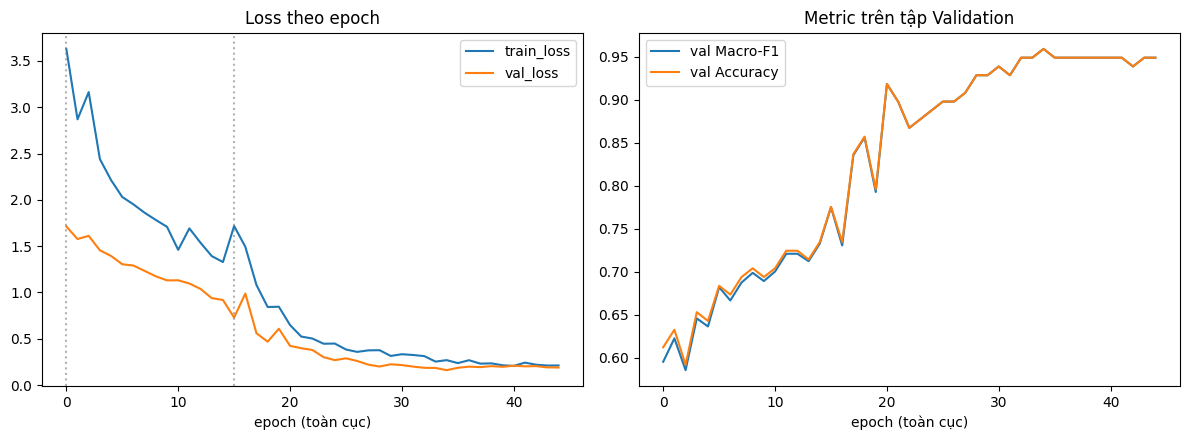

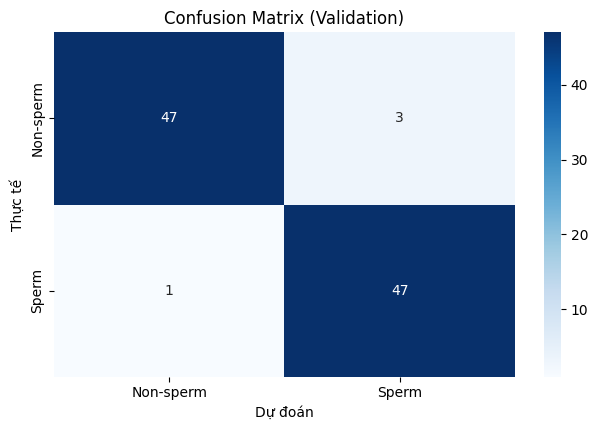

              precision    recall  f1-score   support

   Non-sperm       0.98      0.94      0.96        50
       Sperm       0.94      0.98      0.96        48

    accuracy                           0.96        98
   macro avg       0.96      0.96      0.96        98
weighted avg       0.96      0.96      0.96        98

☁️  Đã lưu 'mobilenetv3_large__kd__L-cn-r5__s42' vào: /content/drive/MyDrive/SpermAI_Benchmark/outputs/Distill/TaskA/mobilenetv3_large__kd__L-cn-r5__s42

🚀 mobilenetv3_large__rekd__F-cn__s42
   logit-teacher=- | ordinal=False | ReKD=feature-teacher convnext_base
   ReKD: C_student=960 -> C_teacher=1024 | 1.66M tham số phụ (chỉ dùng lúc train)


/tmp/ipykernel_801/725966588.py:118: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device.type == "cuda"))


[stage1_head_only] Ep 01/15 | loss=22.5133 (ce=2.446, kd=0.000) rekd[nll=19.154 pr=0.091 kd=0.091] | val_loss=1.6665 | val_acc=0.6224 | val_F1=0.6077 ⭐ | 3.9s
[stage1_head_only] Ep 02/15 | loss=20.0515 (ce=1.840, kd=0.000) rekd[nll=17.317 pr=0.089 kd=0.089] | val_loss=1.4702 | val_acc=0.6531 | val_F1=0.6458 ⭐ | 2.9s
[stage1_head_only] Ep 03/15 | loss=18.5180 (ce=1.395, kd=0.000) rekd[nll=16.226 pr=0.089 kd=0.089] | val_loss=1.4178 | val_acc=0.6735 | val_F1=0.6667 ⭐ | 2.9s
[stage1_head_only] Ep 04/15 | loss=18.0987 (ce=1.556, kd=0.000) rekd[nll=15.625 pr=0.091 kd=0.091] | val_loss=1.3882 | val_acc=0.6327 | val_F1=0.6271    | 2.9s
[stage1_head_only] Ep 05/15 | loss=17.2110 (ce=1.307, kd=0.000) rekd[nll=14.961 pr=0.094 kd=0.094] | val_loss=1.2623 | val_acc=0.6939 | val_F1=0.6892 ⭐ | 2.9s
[stage1_head_only] Ep 06/15 | loss=17.0980 (ce=1.366, kd=0.000) rekd[nll=14.675 pr=0.105 kd=0.105] | val_loss=1.2160 | val_acc=0.7245 | val_F1=0.7179 ⭐ | 2.9s
[stage1_head_only] Ep 07/15 | loss=16.1599 (c

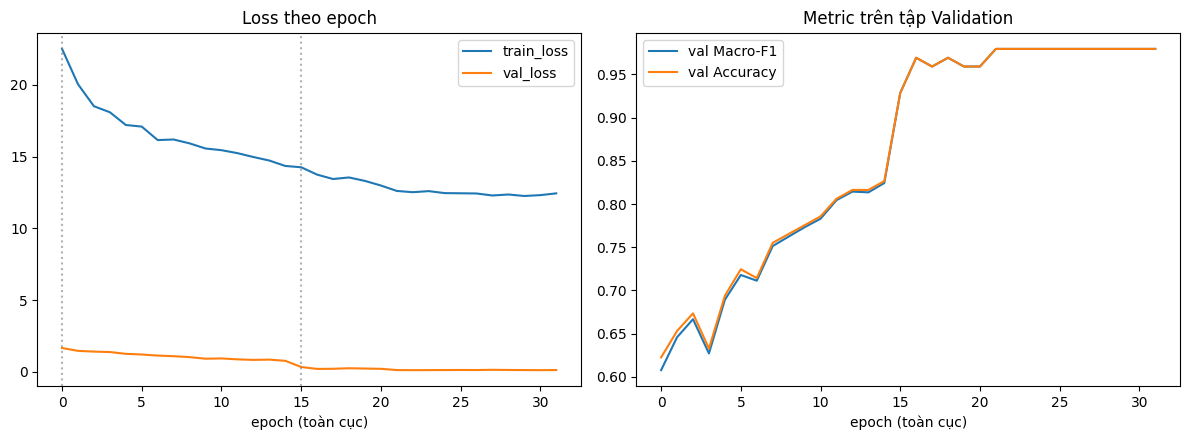

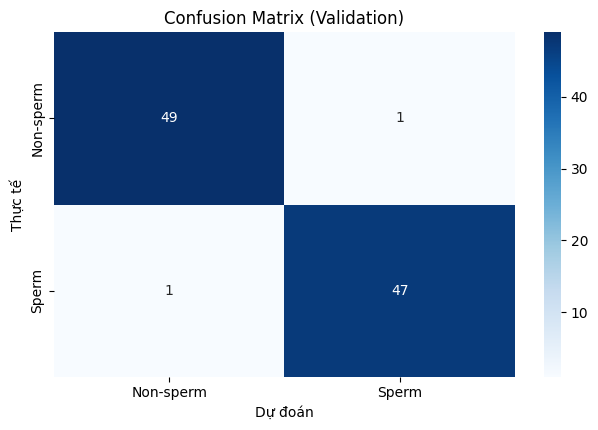

              precision    recall  f1-score   support

   Non-sperm       0.98      0.98      0.98        50
       Sperm       0.98      0.98      0.98        48

    accuracy                           0.98        98
   macro avg       0.98      0.98      0.98        98
weighted avg       0.98      0.98      0.98        98

☁️  Đã lưu 'mobilenetv3_large__rekd__F-cn__s42' vào: /content/drive/MyDrive/SpermAI_Benchmark/outputs/Distill/TaskA/mobilenetv3_large__rekd__F-cn__s42

🚀 mobilenetv3_large__kd_rekd__L-cn-r5__F-cn__s42
   logit-teacher=ensemble | ordinal=False | ReKD=feature-teacher convnext_base
   ReKD: C_student=960 -> C_teacher=1024 | 1.66M tham số phụ (chỉ dùng lúc train)


/tmp/ipykernel_801/725966588.py:118: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device.type == "cuda"))


[stage1_head_only] Ep 01/15 | loss=23.7316 (ce=2.435, kd=4.894) rekd[nll=19.154 pr=0.091 kd=0.091] | val_loss=1.7650 | val_acc=0.6224 | val_F1=0.6077 ⭐ | 5.1s
[stage1_head_only] Ep 02/15 | loss=21.0395 (ce=1.866, kd=3.791) rekd[nll=17.317 pr=0.089 kd=0.089] | val_loss=1.6019 | val_acc=0.6531 | val_F1=0.6436 ⭐ | 5.1s
[stage1_head_only] Ep 03/15 | loss=19.3317 (ce=1.445, kd=2.973) rekd[nll=16.226 pr=0.089 kd=0.089] | val_loss=1.5472 | val_acc=0.6735 | val_F1=0.6667 ⭐ | 5.2s
[stage1_head_only] Ep 04/15 | loss=19.0521 (ce=1.629, kd=3.390) rekd[nll=15.625 pr=0.091 kd=0.091] | val_loss=1.5170 | val_acc=0.6224 | val_F1=0.6157    | 5.2s
[stage1_head_only] Ep 05/15 | loss=18.0441 (ce=1.376, kd=2.904) rekd[nll=14.961 pr=0.094 kd=0.094] | val_loss=1.3910 | val_acc=0.6531 | val_F1=0.6458    | 5.1s
[stage1_head_only] Ep 06/15 | loss=17.9813 (ce=1.473, kd=3.025) rekd[nll=14.675 pr=0.105 kd=0.105] | val_loss=1.3512 | val_acc=0.6735 | val_F1=0.6667    | 5.1s
[stage1_head_only] Ep 07/15 | loss=17.1521 

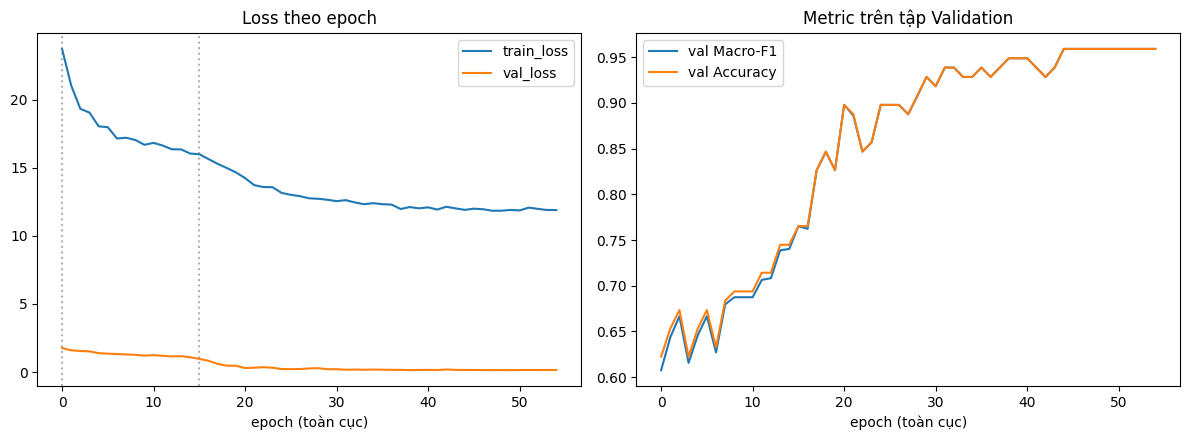

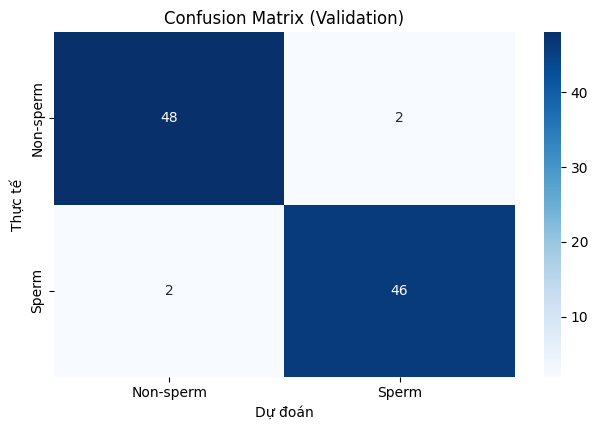

              precision    recall  f1-score   support

   Non-sperm       0.96      0.96      0.96        50
       Sperm       0.96      0.96      0.96        48

    accuracy                           0.96        98
   macro avg       0.96      0.96      0.96        98
weighted avg       0.96      0.96      0.96        98

☁️  Đã lưu 'mobilenetv3_large__kd_rekd__L-cn-r5__F-cn__s42' vào: /content/drive/MyDrive/SpermAI_Benchmark/outputs/Distill/TaskA/mobilenetv3_large__kd_rekd__L-cn-r5__F-cn__s42

🚀 mobilenetv3_large__baseline__s43
   logit-teacher=- | ordinal=False | ReKD=-


/tmp/ipykernel_801/725966588.py:118: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device.type == "cuda"))


[stage1_head_only] Ep 01/15 | loss=2.2310 (ce=2.231, kd=0.000) | val_loss=2.7035 | val_acc=0.4796 | val_F1=0.4782 ⭐ | 2.4s
[stage1_head_only] Ep 02/15 | loss=1.8698 (ce=1.870, kd=0.000) | val_loss=2.6944 | val_acc=0.4898 | val_F1=0.4864 ⭐ | 2.4s
[stage1_head_only] Ep 03/15 | loss=1.4507 (ce=1.451, kd=0.000) | val_loss=2.4941 | val_acc=0.5102 | val_F1=0.5069 ⭐ | 2.3s
[stage1_head_only] Ep 04/15 | loss=1.5636 (ce=1.564, kd=0.000) | val_loss=2.1949 | val_acc=0.5204 | val_F1=0.5192 ⭐ | 2.3s
[stage1_head_only] Ep 05/15 | loss=1.3004 (ce=1.300, kd=0.000) | val_loss=2.1071 | val_acc=0.5510 | val_F1=0.5493 ⭐ | 2.4s
[stage1_head_only] Ep 06/15 | loss=1.0487 (ce=1.049, kd=0.000) | val_loss=1.8500 | val_acc=0.5510 | val_F1=0.5503 ⭐ | 2.3s
[stage1_head_only] Ep 07/15 | loss=0.8998 (ce=0.900, kd=0.000) | val_loss=1.7873 | val_acc=0.5918 | val_F1=0.5917 ⭐ | 2.3s
[stage1_head_only] Ep 08/15 | loss=1.1255 (ce=1.126, kd=0.000) | val_loss=1.6338 | val_acc=0.5918 | val_F1=0.5918 ⭐ | 2.3s
[stage1_head_onl

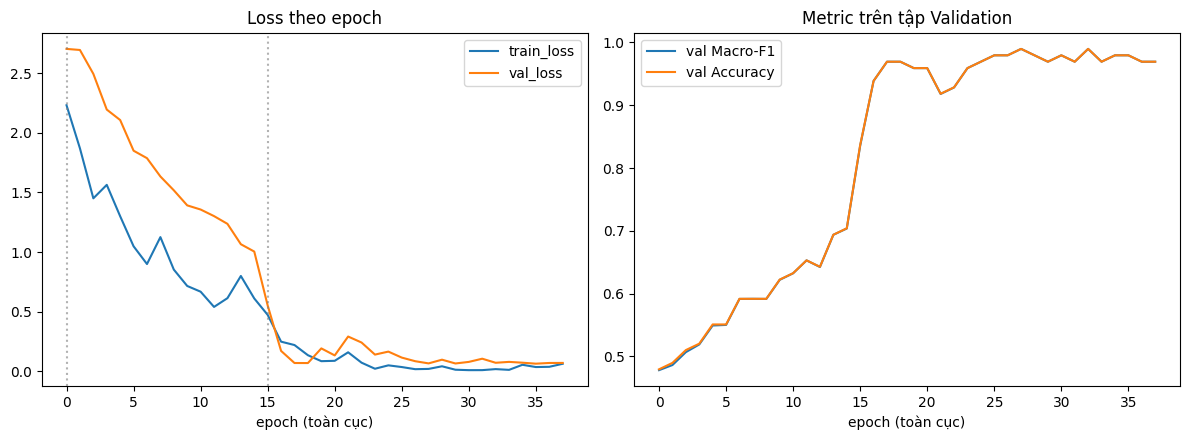

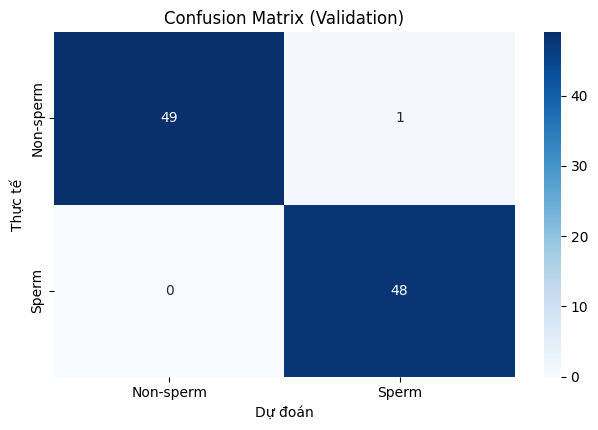

              precision    recall  f1-score   support

   Non-sperm       1.00      0.98      0.99        50
       Sperm       0.98      1.00      0.99        48

    accuracy                           0.99        98
   macro avg       0.99      0.99      0.99        98
weighted avg       0.99      0.99      0.99        98

☁️  Đã lưu 'mobilenetv3_large__baseline__s43' vào: /content/drive/MyDrive/SpermAI_Benchmark/outputs/Distill/TaskA/mobilenetv3_large__baseline__s43

🚀 mobilenetv3_large__kd__L-cn-r5__s43
   logit-teacher=ensemble | ordinal=False | ReKD=-


/tmp/ipykernel_801/725966588.py:118: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device.type == "cuda"))


[stage1_head_only] Ep 01/15 | loss=3.2384 (ce=2.227, kd=4.250) | val_loss=2.7397 | val_acc=0.4592 | val_F1=0.4578 ⭐ | 3.4s
[stage1_head_only] Ep 02/15 | loss=2.8864 (ce=1.890, kd=3.883) | val_loss=2.7592 | val_acc=0.4796 | val_F1=0.4752 ⭐ | 3.3s
[stage1_head_only] Ep 03/15 | loss=2.5630 (ce=1.504, kd=3.622) | val_loss=2.5491 | val_acc=0.5102 | val_F1=0.5069 ⭐ | 3.3s
[stage1_head_only] Ep 04/15 | loss=2.4957 (ce=1.638, kd=3.354) | val_loss=2.2531 | val_acc=0.4898 | val_F1=0.4889    | 3.3s
[stage1_head_only] Ep 05/15 | loss=2.2811 (ce=1.381, kd=3.181) | val_loss=2.1633 | val_acc=0.5000 | val_F1=0.4987    | 3.3s
[stage1_head_only] Ep 06/15 | loss=1.9321 (ce=1.144, kd=2.720) | val_loss=1.9240 | val_acc=0.5408 | val_F1=0.5404 ⭐ | 3.3s
[stage1_head_only] Ep 07/15 | loss=1.7446 (ce=0.984, kd=2.505) | val_loss=1.8793 | val_acc=0.5714 | val_F1=0.5714 ⭐ | 3.3s
[stage1_head_only] Ep 08/15 | loss=2.1044 (ce=1.240, kd=2.969) | val_loss=1.7486 | val_acc=0.5714 | val_F1=0.5714    | 3.3s
[stage1_head_

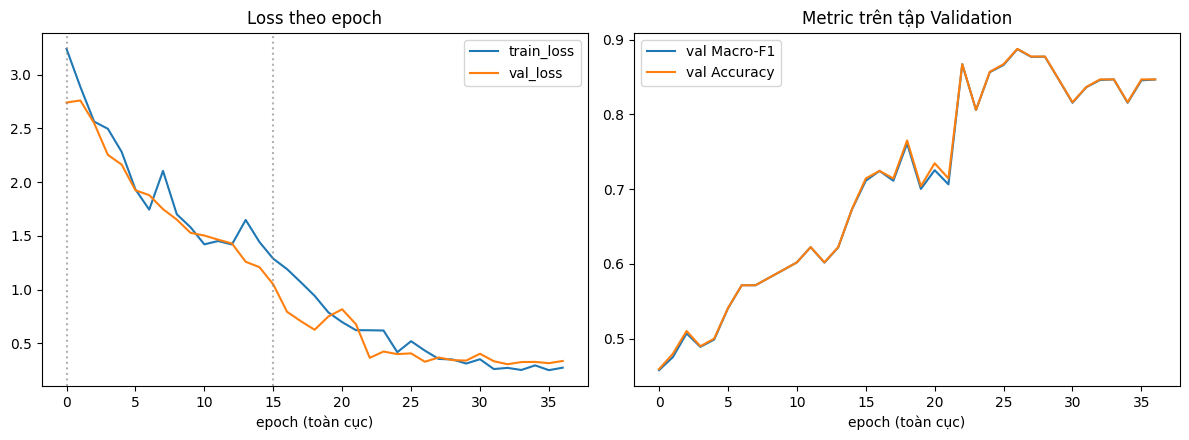

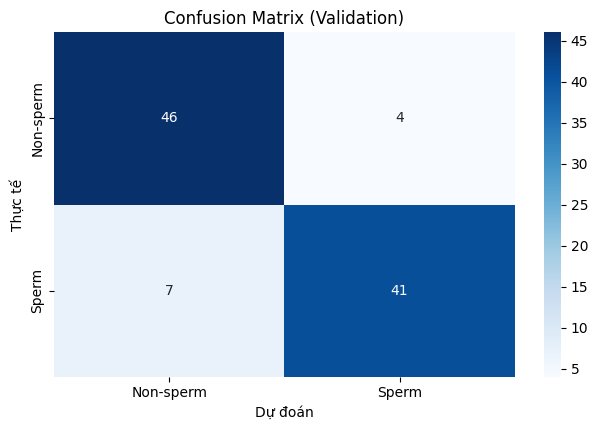

              precision    recall  f1-score   support

   Non-sperm       0.87      0.92      0.89        50
       Sperm       0.91      0.85      0.88        48

    accuracy                           0.89        98
   macro avg       0.89      0.89      0.89        98
weighted avg       0.89      0.89      0.89        98

☁️  Đã lưu 'mobilenetv3_large__kd__L-cn-r5__s43' vào: /content/drive/MyDrive/SpermAI_Benchmark/outputs/Distill/TaskA/mobilenetv3_large__kd__L-cn-r5__s43

🚀 mobilenetv3_large__rekd__F-cn__s43
   logit-teacher=- | ordinal=False | ReKD=feature-teacher convnext_base
   ReKD: C_student=960 -> C_teacher=1024 | 1.66M tham số phụ (chỉ dùng lúc train)


/tmp/ipykernel_801/725966588.py:118: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device.type == "cuda"))


[stage1_head_only] Ep 01/15 | loss=22.4268 (ce=2.312, kd=0.000) rekd[nll=19.120 pr=0.099 kd=0.099] | val_loss=2.7539 | val_acc=0.4694 | val_F1=0.4638 ⭐ | 3.1s
[stage1_head_only] Ep 02/15 | loss=20.5277 (ce=1.895, kd=0.000) rekd[nll=17.486 pr=0.114 kd=0.114] | val_loss=2.7878 | val_acc=0.4694 | val_F1=0.4638    | 3.1s
[stage1_head_only] Ep 03/15 | loss=18.8676 (ce=1.595, kd=0.000) rekd[nll=16.309 pr=0.096 kd=0.096] | val_loss=2.4301 | val_acc=0.5204 | val_F1=0.5143 ⭐ | 3.1s
[stage1_head_only] Ep 04/15 | loss=18.0318 (ce=1.342, kd=0.000) rekd[nll=15.750 pr=0.093 kd=0.093] | val_loss=2.2739 | val_acc=0.5102 | val_F1=0.5051    | 3.0s
[stage1_head_only] Ep 05/15 | loss=17.0700 (ce=1.166, kd=0.000) rekd[nll=14.908 pr=0.099 kd=0.099] | val_loss=2.1450 | val_acc=0.5204 | val_F1=0.5192 ⭐ | 3.0s
[stage1_head_only] Ep 06/15 | loss=16.8156 (ce=1.127, kd=0.000) rekd[nll=14.615 pr=0.107 kd=0.107] | val_loss=1.9636 | val_acc=0.5408 | val_F1=0.5385 ⭐ | 3.0s
[stage1_head_only] Ep 07/15 | loss=16.2836 (

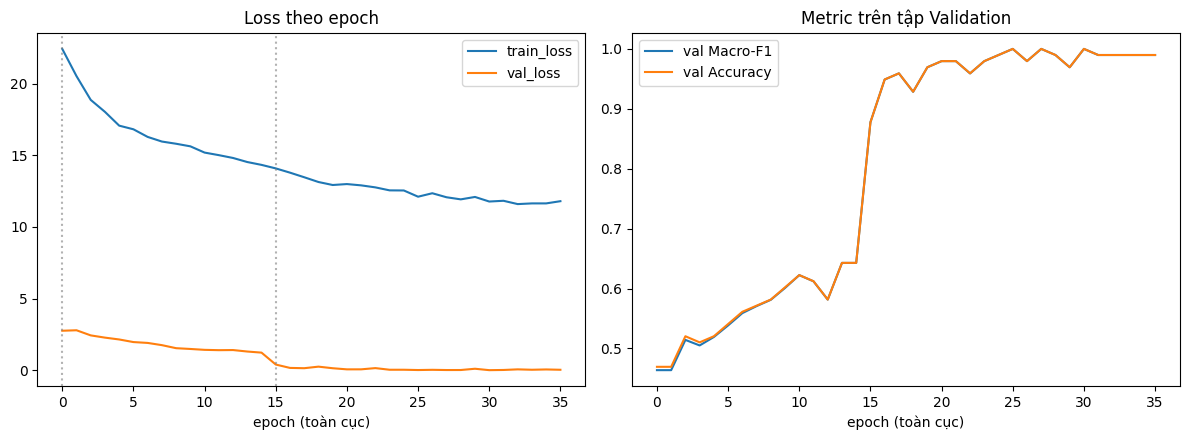

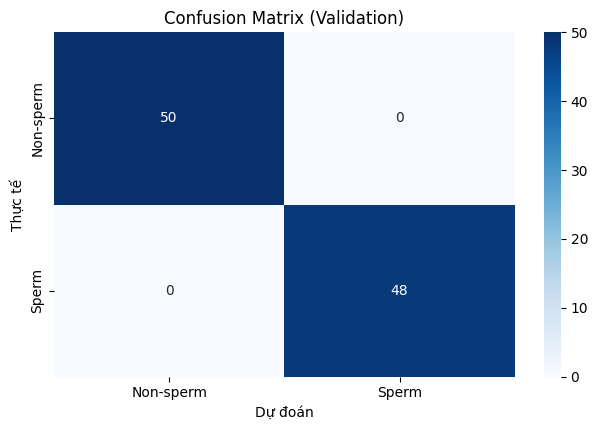

              precision    recall  f1-score   support

   Non-sperm       1.00      1.00      1.00        50
       Sperm       1.00      1.00      1.00        48

    accuracy                           1.00        98
   macro avg       1.00      1.00      1.00        98
weighted avg       1.00      1.00      1.00        98

☁️  Đã lưu 'mobilenetv3_large__rekd__F-cn__s43' vào: /content/drive/MyDrive/SpermAI_Benchmark/outputs/Distill/TaskA/mobilenetv3_large__rekd__F-cn__s43

🚀 mobilenetv3_large__kd_rekd__L-cn-r5__F-cn__s43
   logit-teacher=ensemble | ordinal=False | ReKD=feature-teacher convnext_base
   ReKD: C_student=960 -> C_teacher=1024 | 1.66M tham số phụ (chỉ dùng lúc train)


/tmp/ipykernel_801/725966588.py:118: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device.type == "cuda"))


[stage1_head_only] Ep 01/15 | loss=23.6228 (ce=2.308, kd=4.708) rekd[nll=19.120 pr=0.099 kd=0.099] | val_loss=2.7805 | val_acc=0.4694 | val_F1=0.4638 ⭐ | 5.3s
[stage1_head_only] Ep 02/15 | loss=21.5216 (ce=1.920, kd=3.856) rekd[nll=17.486 pr=0.114 kd=0.114] | val_loss=2.8287 | val_acc=0.4796 | val_F1=0.4730 ⭐ | 5.2s
[stage1_head_only] Ep 03/15 | loss=19.7265 (ce=1.642, kd=3.268) rekd[nll=16.308 pr=0.096 kd=0.096] | val_loss=2.4736 | val_acc=0.5204 | val_F1=0.5143 ⭐ | 5.2s
[stage1_head_only] Ep 04/15 | loss=18.8956 (ce=1.413, kd=3.000) rekd[nll=15.750 pr=0.093 kd=0.093] | val_loss=2.3251 | val_acc=0.5102 | val_F1=0.5051    | 5.2s
[stage1_head_only] Ep 05/15 | loss=17.9115 (ce=1.246, kd=2.765) rekd[nll=14.908 pr=0.099 kd=0.099] | val_loss=2.2197 | val_acc=0.5000 | val_F1=0.4987    | 5.3s
[stage1_head_only] Ep 06/15 | loss=17.6944 (ce=1.220, kd=2.790) rekd[nll=14.615 pr=0.107 kd=0.107] | val_loss=2.0467 | val_acc=0.5204 | val_F1=0.5179 ⭐ | 5.3s
[stage1_head_only] Ep 07/15 | loss=17.1988 (

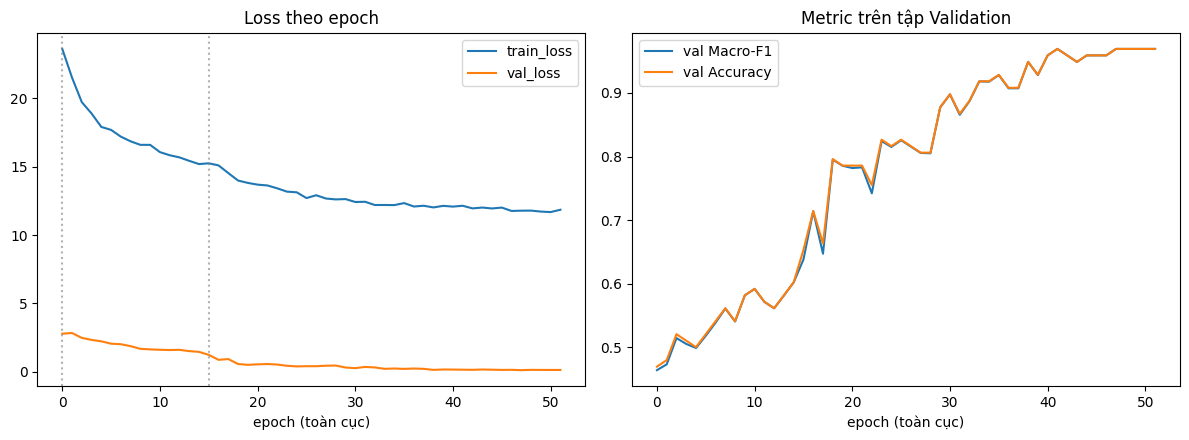

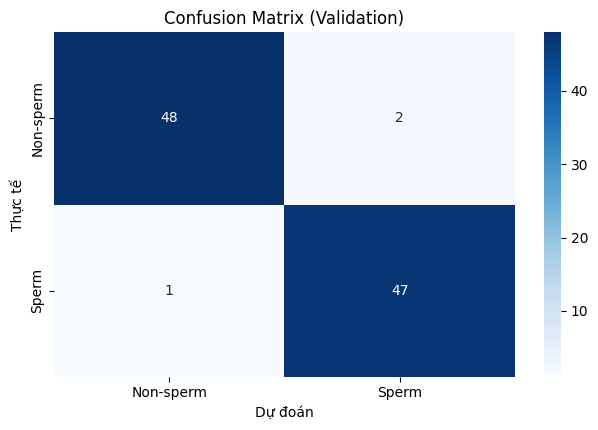

              precision    recall  f1-score   support

   Non-sperm       0.98      0.96      0.97        50
       Sperm       0.96      0.98      0.97        48

    accuracy                           0.97        98
   macro avg       0.97      0.97      0.97        98
weighted avg       0.97      0.97      0.97        98

☁️  Đã lưu 'mobilenetv3_large__kd_rekd__L-cn-r5__F-cn__s43' vào: /content/drive/MyDrive/SpermAI_Benchmark/outputs/Distill/TaskA/mobilenetv3_large__kd_rekd__L-cn-r5__F-cn__s43

🚀 mobilenetv3_large__baseline__s44
   logit-teacher=- | ordinal=False | ReKD=-


/tmp/ipykernel_801/725966588.py:118: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device.type == "cuda"))


[stage1_head_only] Ep 01/15 | loss=3.0065 (ce=3.007, kd=0.000) | val_loss=2.1465 | val_acc=0.5612 | val_F1=0.5601 ⭐ | 2.3s
[stage1_head_only] Ep 02/15 | loss=2.3248 (ce=2.325, kd=0.000) | val_loss=2.1272 | val_acc=0.5408 | val_F1=0.5385    | 2.4s
[stage1_head_only] Ep 03/15 | loss=2.0164 (ce=2.016, kd=0.000) | val_loss=1.9115 | val_acc=0.5918 | val_F1=0.5918 ⭐ | 2.3s
[stage1_head_only] Ep 04/15 | loss=1.7897 (ce=1.790, kd=0.000) | val_loss=1.8509 | val_acc=0.5714 | val_F1=0.5707    | 2.4s
[stage1_head_only] Ep 05/15 | loss=1.5158 (ce=1.516, kd=0.000) | val_loss=1.6934 | val_acc=0.6020 | val_F1=0.6017 ⭐ | 2.4s
[stage1_head_only] Ep 06/15 | loss=1.4095 (ce=1.410, kd=0.000) | val_loss=1.5450 | val_acc=0.6020 | val_F1=0.6020 ⭐ | 2.4s
[stage1_head_only] Ep 07/15 | loss=1.3051 (ce=1.305, kd=0.000) | val_loss=1.3877 | val_acc=0.6531 | val_F1=0.6529 ⭐ | 2.3s
[stage1_head_only] Ep 08/15 | loss=1.0434 (ce=1.043, kd=0.000) | val_loss=1.3457 | val_acc=0.6327 | val_F1=0.6325    | 2.4s
[stage1_head_

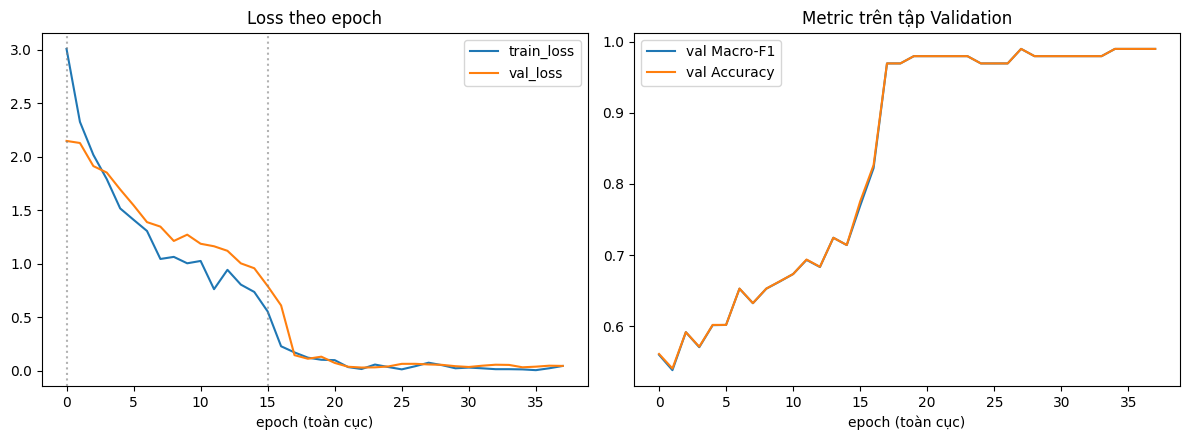

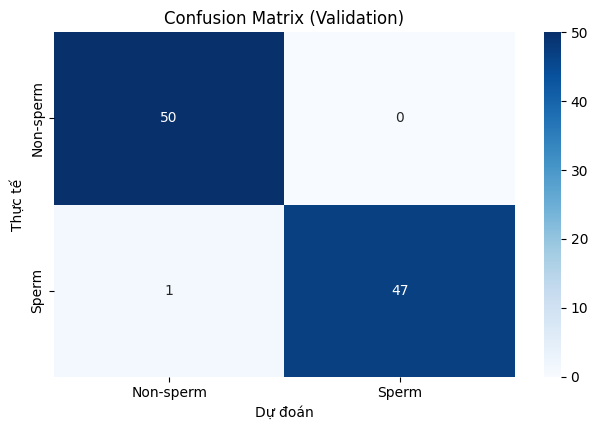

              precision    recall  f1-score   support

   Non-sperm       0.98      1.00      0.99        50
       Sperm       1.00      0.98      0.99        48

    accuracy                           0.99        98
   macro avg       0.99      0.99      0.99        98
weighted avg       0.99      0.99      0.99        98

☁️  Đã lưu 'mobilenetv3_large__baseline__s44' vào: /content/drive/MyDrive/SpermAI_Benchmark/outputs/Distill/TaskA/mobilenetv3_large__baseline__s44

🚀 mobilenetv3_large__kd__L-cn-r5__s44
   logit-teacher=ensemble | ordinal=False | ReKD=-


/tmp/ipykernel_801/725966588.py:118: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device.type == "cuda"))


[stage1_head_only] Ep 01/15 | loss=4.7811 (ce=2.982, kd=6.580) | val_loss=2.1921 | val_acc=0.5612 | val_F1=0.5601 ⭐ | 3.4s
[stage1_head_only] Ep 02/15 | loss=3.5578 (ce=2.326, kd=4.790) | val_loss=2.2322 | val_acc=0.5306 | val_F1=0.5298    | 3.3s
[stage1_head_only] Ep 03/15 | loss=3.0612 (ce=2.080, kd=4.042) | val_loss=2.0596 | val_acc=0.5408 | val_F1=0.5408    | 3.3s
[stage1_head_only] Ep 04/15 | loss=2.7654 (ce=1.868, kd=3.663) | val_loss=2.0084 | val_acc=0.5510 | val_F1=0.5510    | 3.4s
[stage1_head_only] Ep 05/15 | loss=2.5435 (ce=1.627, kd=3.460) | val_loss=1.9223 | val_acc=0.5612 | val_F1=0.5612 ⭐ | 3.4s
[stage1_head_only] Ep 06/15 | loss=2.5055 (ce=1.616, kd=3.395) | val_loss=1.8329 | val_acc=0.5816 | val_F1=0.5816 ⭐ | 3.3s
[stage1_head_only] Ep 07/15 | loss=2.4084 (ce=1.567, kd=3.250) | val_loss=1.7219 | val_acc=0.6122 | val_F1=0.6121 ⭐ | 3.3s
[stage1_head_only] Ep 08/15 | loss=2.0986 (ce=1.332, kd=2.865) | val_loss=1.7375 | val_acc=0.5612 | val_F1=0.5612    | 3.4s
[stage1_head

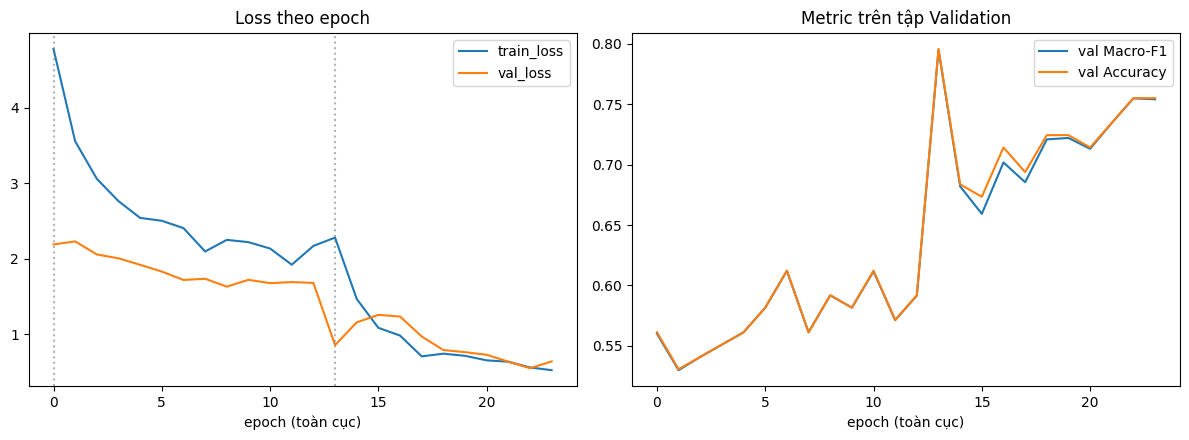

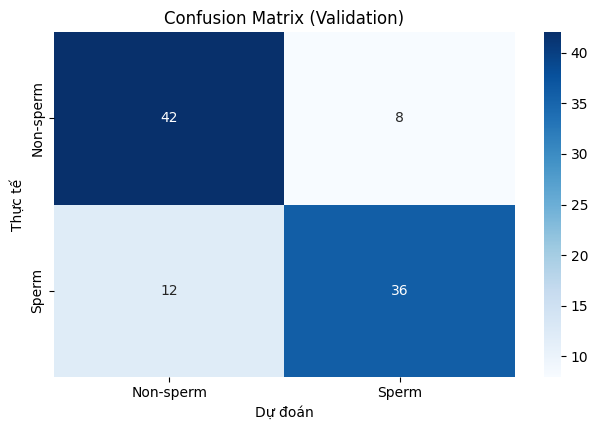

              precision    recall  f1-score   support

   Non-sperm       0.78      0.84      0.81        50
       Sperm       0.82      0.75      0.78        48

    accuracy                           0.80        98
   macro avg       0.80      0.79      0.80        98
weighted avg       0.80      0.80      0.80        98

☁️  Đã lưu 'mobilenetv3_large__kd__L-cn-r5__s44' vào: /content/drive/MyDrive/SpermAI_Benchmark/outputs/Distill/TaskA/mobilenetv3_large__kd__L-cn-r5__s44

🚀 mobilenetv3_large__rekd__F-cn__s44
   logit-teacher=- | ordinal=False | ReKD=feature-teacher convnext_base
   ReKD: C_student=960 -> C_teacher=1024 | 1.66M tham số phụ (chỉ dùng lúc train)


/tmp/ipykernel_801/725966588.py:118: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device.type == "cuda"))


[stage1_head_only] Ep 01/15 | loss=23.2357 (ce=3.086, kd=0.000) rekd[nll=19.192 pr=0.095 kd=0.095] | val_loss=2.1895 | val_acc=0.5714 | val_F1=0.5707 ⭐ | 3.0s
[stage1_head_only] Ep 02/15 | loss=20.8404 (ce=2.521, kd=0.000) rekd[nll=17.194 pr=0.112 kd=0.112] | val_loss=2.0974 | val_acc=0.5510 | val_F1=0.5508    | 3.2s
[stage1_head_only] Ep 03/15 | loss=19.1883 (ce=1.864, kd=0.000) rekd[nll=16.410 pr=0.091 kd=0.091] | val_loss=1.9592 | val_acc=0.5816 | val_F1=0.5816 ⭐ | 3.0s
[stage1_head_only] Ep 04/15 | loss=18.4244 (ce=1.810, kd=0.000) rekd[nll=15.659 pr=0.095 kd=0.095] | val_loss=1.8759 | val_acc=0.5918 | val_F1=0.5903 ⭐ | 3.0s
[stage1_head_only] Ep 05/15 | loss=17.6788 (ce=1.673, kd=0.000) rekd[nll=14.915 pr=0.109 kd=0.109] | val_loss=1.7249 | val_acc=0.6020 | val_F1=0.6020 ⭐ | 3.0s
[stage1_head_only] Ep 06/15 | loss=17.3493 (ce=1.601, kd=0.000) rekd[nll=14.588 pr=0.115 kd=0.115] | val_loss=1.6659 | val_acc=0.5918 | val_F1=0.5917    | 3.1s
[stage1_head_only] Ep 07/15 | loss=16.5175 (

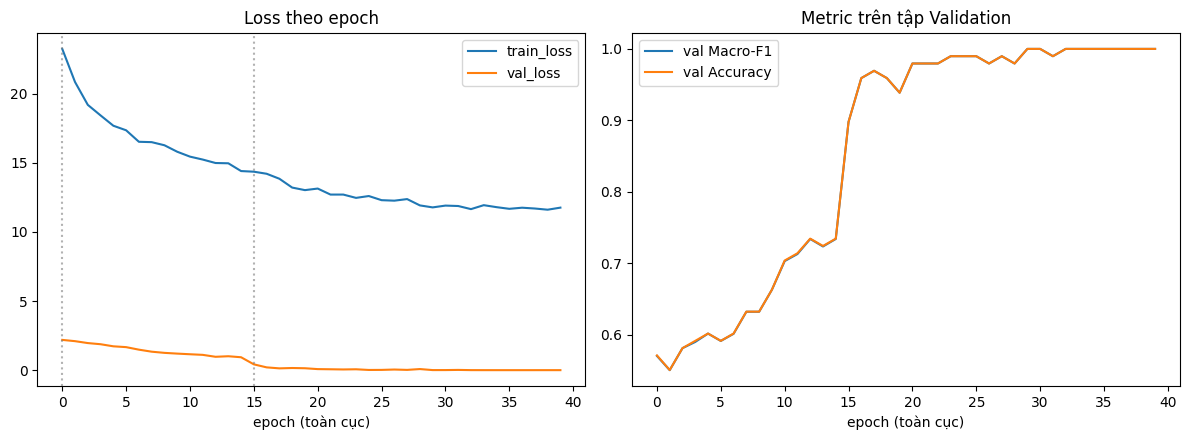

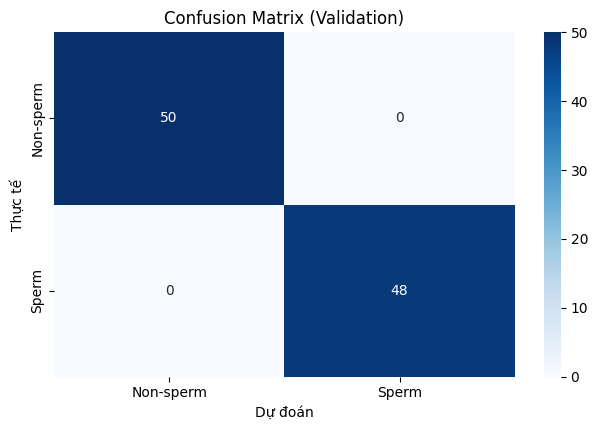

              precision    recall  f1-score   support

   Non-sperm       1.00      1.00      1.00        50
       Sperm       1.00      1.00      1.00        48

    accuracy                           1.00        98
   macro avg       1.00      1.00      1.00        98
weighted avg       1.00      1.00      1.00        98

☁️  Đã lưu 'mobilenetv3_large__rekd__F-cn__s44' vào: /content/drive/MyDrive/SpermAI_Benchmark/outputs/Distill/TaskA/mobilenetv3_large__rekd__F-cn__s44

🚀 mobilenetv3_large__kd_rekd__L-cn-r5__F-cn__s44
   logit-teacher=ensemble | ordinal=False | ReKD=feature-teacher convnext_base
   ReKD: C_student=960 -> C_teacher=1024 | 1.66M tham số phụ (chỉ dùng lúc train)


/tmp/ipykernel_801/725966588.py:118: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device.type == "cuda"))


[stage1_head_only] Ep 01/15 | loss=24.9725 (ce=3.068, kd=6.577) rekd[nll=19.192 pr=0.095 kd=0.095] | val_loss=2.2394 | val_acc=0.5408 | val_F1=0.5408 ⭐ | 5.2s
[stage1_head_only] Ep 02/15 | loss=22.0535 (ce=2.518, kd=4.954) rekd[nll=17.195 pr=0.112 kd=0.112] | val_loss=2.1996 | val_acc=0.5306 | val_F1=0.5304    | 5.2s
[stage1_head_only] Ep 03/15 | loss=20.1650 (ce=1.914, kd=3.769) rekd[nll=16.409 pr=0.091 kd=0.091] | val_loss=2.0794 | val_acc=0.5612 | val_F1=0.5608 ⭐ | 5.3s
[stage1_head_only] Ep 04/15 | loss=19.4334 (ce=1.891, kd=3.746) rekd[nll=15.656 pr=0.095 kd=0.095] | val_loss=2.0011 | val_acc=0.5714 | val_F1=0.5707 ⭐ | 5.3s
[stage1_head_only] Ep 05/15 | loss=18.7449 (ce=1.753, kd=3.727) rekd[nll=14.912 pr=0.109 kd=0.109] | val_loss=1.8625 | val_acc=0.5816 | val_F1=0.5816 ⭐ | 5.3s
[stage1_head_only] Ep 06/15 | loss=18.3329 (ce=1.719, kd=3.456) rekd[nll=14.585 pr=0.115 kd=0.115] | val_loss=1.8322 | val_acc=0.5816 | val_F1=0.5816    | 5.3s
[stage1_head_only] Ep 07/15 | loss=17.4237 (

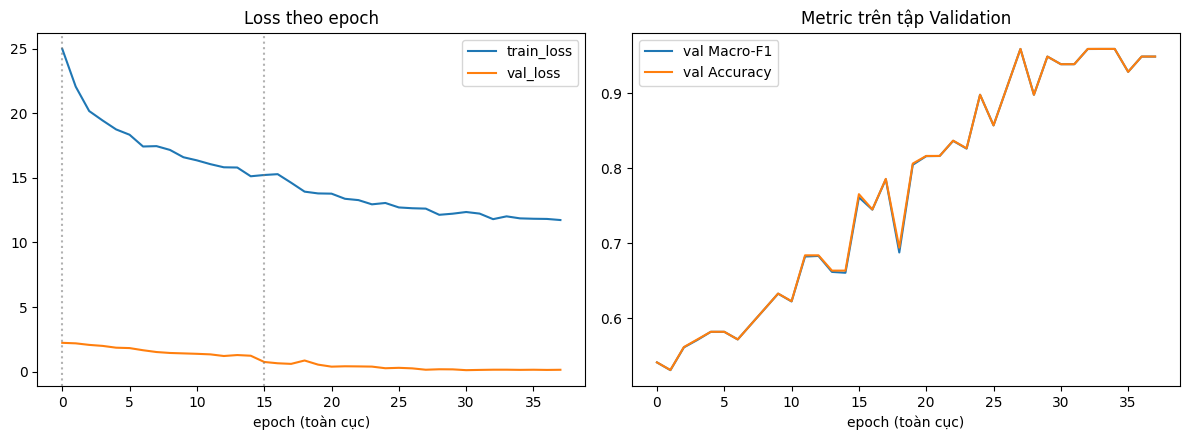

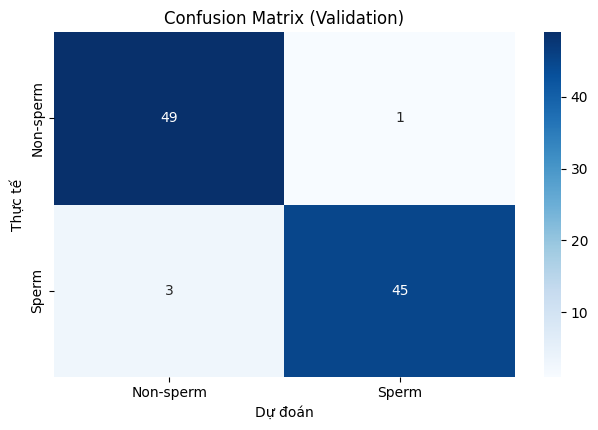

              precision    recall  f1-score   support

   Non-sperm       0.94      0.98      0.96        50
       Sperm       0.98      0.94      0.96        48

    accuracy                           0.96        98
   macro avg       0.96      0.96      0.96        98
weighted avg       0.96      0.96      0.96        98

☁️  Đã lưu 'mobilenetv3_large__kd_rekd__L-cn-r5__F-cn__s44' vào: /content/drive/MyDrive/SpermAI_Benchmark/outputs/Distill/TaskA/mobilenetv3_large__kd_rekd__L-cn-r5__F-cn__s44

🎉 HOÀN TẤT. Chạy cell tổng hợp bên dưới để so sánh.


In [ ]:
if __name__ == "__main__":
    # ================= ĐIỀU CHỈNH CÁC THÔNG SỐ NÀY =================
    STUDENTS_TO_RUN = ["mobilenetv3_large"]                      # hoặc "ALL"
    VARIANTS_TO_RUN = (["baseline", "kd", "kd_ord", "rekd", "kd_rekd"] if TASK == "B"
                       else ["baseline", "kd", "rekd", "kd_rekd"])
    SEEDS           = [42, 43, 44]

    LOGIT_TEACHER_TOPK  = 2          # số teacher trong ensemble (chọn theo VAL Macro-F1)
    LOGIT_TEACHER_KEYS  = None       # hoặc chỉ định tay, vd. ["swin_base", "vit_base"]
    FEATURE_TEACHER_KEY = None       # hoặc vd. "swin_base"; None = teacher VAL F1 cao nhất

    STAGE1_EPOCHS, STAGE1_PATIENCE = 15, 6
    STAGE2_EPOCHS, STAGE2_PATIENCE = 50, 10
    FORCE_RERUN = False              # True: chạy lại cả khi đã có best_model.pth
    # =================================================================

    students = list(STUDENT_CONFIGS.keys()) if STUDENTS_TO_RUN == "ALL" else list(STUDENTS_TO_RUN)
    for s in students:
        assert s in STUDENT_CONFIGS, f"Student '{s}' chưa có trong STUDENT_CONFIGS."
    for v in VARIANTS_TO_RUN:
        assert v in VARIANT_CFGS, f"Variant '{v}' không hợp lệ."
        assert not (VARIANT_CFGS[v]["ordinal"] and TASK == "A"), "Biến thể ordinal chỉ dùng cho Task B."
    need_logit = any(VARIANT_CFGS[v]["use_teacher"] for v in VARIANTS_TO_RUN)
    need_feat  = any(VARIANT_CFGS[v]["use_rekd"] for v in VARIANTS_TO_RUN)

    # ---- Ensemble teacher cho logit-KD ----
    teacher, teacher_specs, logit_names = None, {}, []
    if need_logit:
        chosen = select_teachers(TEACHER_DIR, LOGIT_TEACHER_TOPK, LOGIT_TEACHER_KEYS)
        teacher, teacher_specs = load_teacher_ensemble(chosen, class_to_idx)
        logit_names = [r["model"] for r in chosen]

        ens_res = evaluate_ensemble(teacher, teacher_specs, val_list)
        print("\n📊 VAL — từng teacher vs ensemble:")
        for k, v in ens_res.items():
            print(f"   {k:24s} acc={v['acc']:.4f}  macro-F1={v['f1_macro']:.4f}")
        ens_dir = os.path.join(OUTPUT_DRIVE_DIR, "_teacher_ensemble")
        os.makedirs(ens_dir, exist_ok=True)
        with open(os.path.join(ens_dir, f"val_metrics__{make_tag(logit_names, None)}.json"), "w") as f:
            json.dump({"teachers": logit_names, "val_metrics": ens_res}, f, indent=2)

    # ---- Feature teacher cho ReKD ----
    feat_teacher, feat_name = None, None
    if need_feat:
        frow = select_teachers(TEACHER_DIR, 1, [FEATURE_TEACHER_KEY] if FEATURE_TEACHER_KEY else None)[0]
        feat_teacher = load_feature_teacher(frow, teacher, class_to_idx)
        feat_name = frow["model"]

    # ---- Chạy: seed ngoài cùng (xong mỗi seed là có đủ bảng so sánh) ----
    for seed in SEEDS:
        for student_key in students:
            for variant in VARIANTS_TO_RUN:
                tag = variant_tag(variant, logit_names, feat_name)
                run_name = make_run_name(student_key, variant, seed, tag)
                if os.path.exists(os.path.join(OUTPUT_DRIVE_DIR, run_name, "best_model.pth")) and not FORCE_RERUN:
                    print(f"⏭️  Bỏ qua '{run_name}' (đã có kết quả; đặt FORCE_RERUN=True để chạy lại).")
                    continue

                student, history_df, best_f1, s_spec, val_loader, skey = train_student(
                    student_key, variant, seed, run_name, teacher, teacher_specs, feat_teacher,
                    STAGE1_EPOCHS, STAGE1_PATIENCE, STAGE2_EPOCHS, STAGE2_PATIENCE)

                vm, vp, vl = evaluate_student(student, val_loader, skey, rank_of_idx)
                print("\n📊 VAL cuối cùng:", {k: round(v, 4) for k, v in vm.items()})
                vc = VARIANT_CFGS[variant]
                extra = {"teacher_tag": tag,
                         "teachers": logit_names if vc["use_teacher"] else [],        # logit-teacher
                         "feature_teacher": feat_name if vc["use_rekd"] else None,
                         "rekd_cfg": REKD_CFG if vc["use_rekd"] else None}
                save_student_outputs(run_name, student_key, variant, seed, student, history_df,
                                     vm, vp, vl, s_spec, extra)
                del student
                torch.cuda.empty_cache()

    del teacher, feat_teacher
    torch.cuda.empty_cache()
    print("\n🎉 HOÀN TẤT. Chạy cell tổng hợp bên dưới để so sánh.")


## 16. 📋 Bảng tổng hợp (VALIDATION) & so sánh **theo từng seed** với baseline

Cách đọc:
- Bảng đầu: trung bình ± độ lệch chuẩn qua các seed, theo `config` = biến thể + tag teacher.
- Bảng `pivot`: mỗi hàng là 1 seed, mỗi cột là 1 cấu hình → thấy ngay seed nào thắng/thua baseline.
- Bảng `mean_diff`: chênh lệch so với `baseline` **cùng seed**. Với F1 thì `> 0` là tốt hơn; với `val_ord_mae` thì `< 0` là tốt hơn.
- Cột `thang/hoa/thua`: số seed thắng / hòa / thua baseline, trong đó chênh lệch ≤ 0.01 (~0.6 ảnh) được coi là **hòa** (tránh đếm chênh lệch 0.0006 là "thắng").
- Cột `verdict` (chỉ cho F1) là **quy ước tham khảo**, không phải kiểm định thống kê: cần ≥ 3 seed, **thắng rõ** ở ≥ 2/3 số seed và `mean_diff` > max(0.02, std). Tập val chỉ ~61–98 ảnh nên ngưỡng 0.02 ≈ 1–2 ảnh.
- Run cũ (tên không có tag) vẫn được đọc: tag được suy ra từ `config.json`. Nếu cùng (student, variant, tag, seed) có nhiều thư mục, chỉ giữ cái **mới nhất**.


===== Tổng hợp theo (student, config) =====


,student,config,n_seeds,val_f1_mean,val_f1_std,val_acc_mean,val_ord_mae,params_M,size_mb,lat_cpu_ms
0,efficientnet_lite0,baseline,1,0.9796,NaN,0.9796,NaN,3.374,13.49,28.0800
1,efficientnet_lite0,kd [L-cn-r5],1,0.9284,NaN,0.9286,NaN,3.374,13.49,44.2700
2,mobilenetv3_large,baseline,3,0.9898,0.0000,0.9898,NaN,4.205,16.82,20.4567
3,mobilenetv3_large,kd [L-cn-r5],3,0.8806,0.0822,0.8810,NaN,4.205,16.82,20.9667
4,mobilenetv3_large,kd_rekd [L-cn-r5__F-cn],3,0.9626,0.0059,0.9626,NaN,4.205,16.82,20.6233
5,mobilenetv3_large,rekd [F-cn],3,0.9932,0.0118,0.9932,NaN,4.205,16.82,20.8700



----- val_f1 theo từng seed -----


config                   baseline  kd [L-cn-r5]  kd_rekd [L-cn-r5__F-cn]  \
student            seed                                                    
efficientnet_lite0 42      0.9796        0.9284                      NaN   
mobilenetv3_large  42      0.9898        0.9592                   0.9592   
                   43      0.9898        0.8875                   0.9694   
                   44      0.9898        0.7952                   0.9591   

config                   rekd [F-cn]  
student            seed               
efficientnet_lite0 42            NaN  
mobilenetv3_large  42         0.9796  
                   43         1.0000  
                   44         1.0000


----- val_f1: chênh lệch so với baseline cùng seed (dương = tốt hơn) -----


,student,config,n_seeds,mean_diff,std_diff,thang/hoa/thua,verdict
0,efficientnet_lite0,kd [L-cn-r5],1,-0.0512,NaN,0/0/1,cần >= 3 seed
1,mobilenetv3_large,kd [L-cn-r5],3,-0.1092,0.0822,0/0/3,⚠️ chưa đủ bằng chứng
2,mobilenetv3_large,kd_rekd [L-cn-r5__F-cn],3,-0.0272,0.0059,0/0/3,⚠️ chưa đủ bằng chứng
3,mobilenetv3_large,rekd [F-cn],3,0.0034,0.0118,2/0/1,⚠️ chưa đủ bằng chứng



Teacher (VAL):
  [val_metrics.json]  teachers = ['convnext_base', 'resnet50']
     convnext_base            acc=0.9898  macro-F1=0.9898
     resnet50                 acc=0.9592  macro-F1=0.9592
     ENSEMBLE(mean logits)    acc=0.9898  macro-F1=0.9898
  [val_metrics__L-cn-r5.json]  teachers = ['convnext_base', 'resnet50']
     convnext_base            acc=0.9898  macro-F1=0.9898
     resnet50                 acc=0.9592  macro-F1=0.9592
     ENSEMBLE(mean logits)    acc=0.9898  macro-F1=0.9898


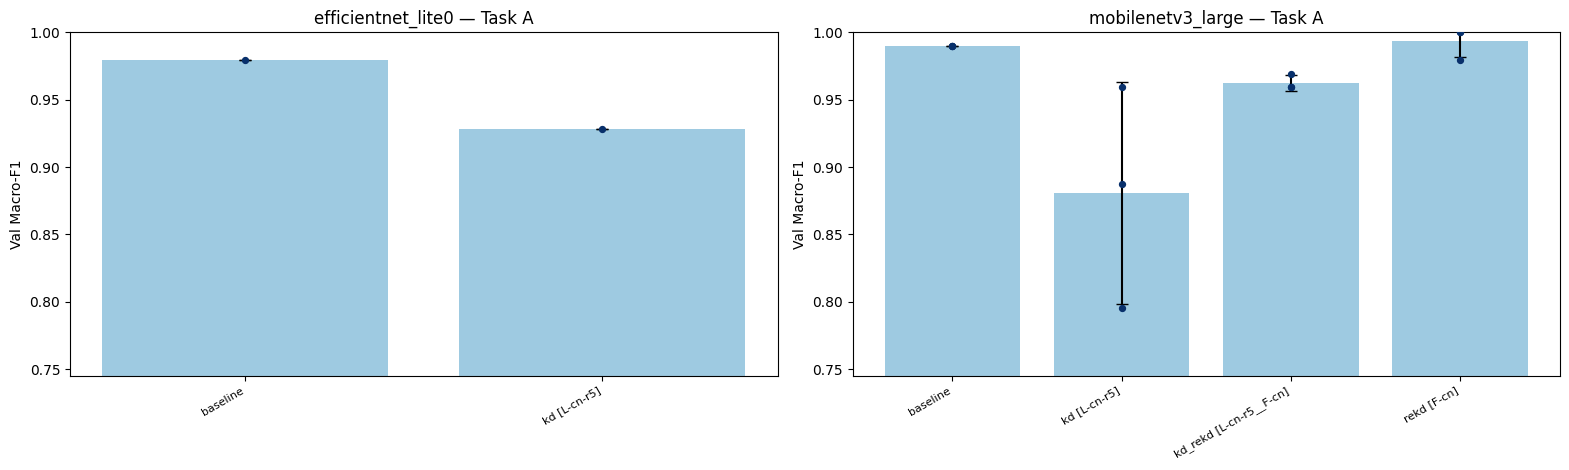

In [ ]:
rows = []
for d in sorted(os.listdir(OUTPUT_DRIVE_DIR)):
    p = os.path.join(OUTPUT_DRIVE_DIR, d, "config.json")
    if not os.path.isfile(p):
        continue
    with open(p, "r") as f:
        c = json.load(f)
    vm = c["val_metrics"]
    tag = c.get("teacher_tag") or variant_tag(c["variant"], c.get("teachers", []), c.get("feature_teacher"))
    rows.append({"run": d, "student": c["student_key"], "variant": c["variant"], "tag": tag, "seed": c["seed"],
                 "val_f1": vm["f1_macro"], "val_acc": vm["acc"], "val_ord_mae": vm.get("ord_mae"),
                 "params_M": c["params_M"], "size_mb": c["size_mb_fp32"],
                 "lat_cpu_ms": c.get("latency_ms_cpu"), "lat_gpu_ms": c.get("latency_ms_gpu"),
                 "mtime": os.path.getmtime(p)})

df_runs = pd.DataFrame(rows)
if df_runs.empty:
    print("Chưa có run nào.")
else:
    df_runs = (df_runs.sort_values("mtime")
               .drop_duplicates(["student", "variant", "tag", "seed"], keep="last")
               .reset_index(drop=True))
    df_runs["config"] = [v if t == "noT" else f"{v} [{t}]" for v, t in zip(df_runs["variant"], df_runs["tag"])]

    agg = (df_runs.groupby(["student", "config"])
           .agg(n_seeds=("seed", "nunique"),
                val_f1_mean=("val_f1", "mean"), val_f1_std=("val_f1", "std"),
                val_acc_mean=("val_acc", "mean"), val_ord_mae=("val_ord_mae", "mean"),
                params_M=("params_M", "first"), size_mb=("size_mb", "first"),
                lat_cpu_ms=("lat_cpu_ms", "mean"))
           .round(4).reset_index())
    print("===== Tổng hợp theo (student, config) =====")
    display(agg)
    agg.to_csv(os.path.join(OUTPUT_DRIVE_DIR, "distill_summary_val.csv"), index=False)

    def compare_vs_baseline(df, metric, higher_is_better=True, tol=0.01):
        pv = df.pivot_table(index=["student", "seed"], columns="config", values=metric)
        if "baseline" not in pv.columns:
            print("Chưa có baseline để so sánh."); return None
        print(f"\n----- {metric} theo từng seed -----")
        display(pv.round(4))
        diff = pv.drop(columns="baseline").sub(pv["baseline"], axis=0)
        out = []
        for stu, g in diff.groupby(level="student"):
            for col in g.columns:
                d = g[col].dropna()
                if d.empty:
                    continue
                better = d if higher_is_better else -d          # > 0 nghĩa là tốt hơn baseline
                wins   = int((better > tol).sum())               # thắng rõ (hơn > tol)
                ties   = int((better.abs() <= tol).sum())        # hòa (chênh <= tol, ~0.6 ảnh)
                losses = int((better < -tol).sum())              # thua rõ
                row = {"student": stu, "config": col, "n_seeds": len(d),
                       "mean_diff": d.mean(), "std_diff": d.std() if len(d) > 1 else float("nan"),
                       "thang/hoa/thua": f"{wins}/{ties}/{losses}"}
                if higher_is_better:
                    if len(d) < 3:
                        row["verdict"] = "cần >= 3 seed"
                    else:
                        ok = wins >= int(np.ceil(2 * len(d) / 3)) and d.mean() > max(0.02, d.std())
                        row["verdict"] = "✅ có dấu hiệu tốt hơn" if ok else "⚠️ chưa đủ bằng chứng"
                out.append(row)
        res = pd.DataFrame(out).round(4)
        print(f"\n----- {metric}: chênh lệch so với baseline cùng seed "
              f"({'dương = tốt hơn' if higher_is_better else 'âm = tốt hơn'}) -----")
        display(res)
        return res

    cmp_f1 = compare_vs_baseline(df_runs, "val_f1", higher_is_better=True)
    if df_runs["val_ord_mae"].notna().any():
        cmp_mae = compare_vs_baseline(df_runs, "val_ord_mae", higher_is_better=False)
    if cmp_f1 is not None:
        cmp_f1.to_csv(os.path.join(OUTPUT_DRIVE_DIR, "distill_compare_vs_baseline_f1.csv"), index=False)

    # ---- Teacher (val) ----
    print("\nTeacher (VAL):")
    for fpath in sorted(glob.glob(os.path.join(OUTPUT_DRIVE_DIR, "_teacher_ensemble", "val_metrics*.json"))):
        with open(fpath, "r") as f:
            ej = json.load(f)
        print(f"  [{os.path.basename(fpath)}]  teachers = {ej['teachers']}")
        for k, v in ej["val_metrics"].items():
            print(f"     {k:24s} acc={v['acc']:.4f}  macro-F1={v['f1_macro']:.4f}")

    # ---- Biểu đồ: Macro-F1 trung bình (cột) + từng seed (chấm) ----
    stus = list(agg["student"].unique())
    fig, axes = plt.subplots(1, len(stus), figsize=(max(6, 1.3 * agg.shape[0] / max(len(stus), 1) + 4) * len(stus), 4.8),
                             squeeze=False)
    for ax, stu in zip(axes[0], stus):
        a = agg[agg["student"] == stu].reset_index(drop=True)
        ax.bar(range(len(a)), a["val_f1_mean"], color="#9ecae1", yerr=a["val_f1_std"].fillna(0), capsize=4)
        for j, cfg in enumerate(a["config"]):
            pts = df_runs[(df_runs["student"] == stu) & (df_runs["config"] == cfg)]["val_f1"]
            ax.scatter([j] * len(pts), pts, color="#08306b", s=18, zorder=3)
        ax.set_xticks(range(len(a))); ax.set_xticklabels(a["config"], rotation=30, ha="right", fontsize=8)
        lo = max(0.0, float(df_runs["val_f1"].min()) - 0.05)
        ax.set_ylim(lo, min(1.0, float(df_runs["val_f1"].max()) + 0.03))
        ax.set_ylabel("Val Macro-F1"); ax.set_title(f"{stu} — Task {TASK}")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DRIVE_DIR, "distill_compare_val.png"), dpi=150)
    plt.show()


In [ ]:
   for run in sorted(os.listdir(OUTPUT_DRIVE_DIR)):
       p = f"{OUTPUT_DRIVE_DIR}/{run}/history.csv"
       if "rekd" in run and os.path.exists(p):
           h = pd.read_csv(p)
           cols = [c for c in h.columns if c.startswith("train_rk_")]
           print(run); print(h[cols].iloc[[0, len(h)//2, -1]].round(3))

mobilenetv3_large__kd_rekd__L-cn-r5__F-cn__s42
    train_rk_nll  train_rk_pr  train_rk_kd
0         19.154        0.091        0.091
27        10.511        0.197        0.197
54         9.462        0.229        0.229
mobilenetv3_large__kd_rekd__L-cn-r5__F-cn__s43
    train_rk_nll  train_rk_pr  train_rk_kd
0         19.120        0.099        0.099
26        10.540        0.195        0.195
51         9.077        0.262        0.262
mobilenetv3_large__kd_rekd__L-cn-r5__F-cn__s44
    train_rk_nll  train_rk_pr  train_rk_kd
0         19.192        0.095        0.095
19        11.137        0.180        0.180
37         9.195        0.236        0.236
mobilenetv3_large__rekd__F-cn__s42
    train_rk_nll  train_rk_pr  train_rk_kd
0         19.154        0.091        0.091
16        11.596        0.173        0.173
31        10.419        0.197        0.197
mobilenetv3_large__rekd__F-cn__s43
    train_rk_nll  train_rk_pr  train_rk_kd
0         19.120        0.099        0.099
18        11.34

## 17. (Tùy chọn) Ensemble Teacher trên TEST

Chỉ chạy **một lần ở cuối**, sau khi đã chốt cấu hình, để có số "Teacher" đặt cạnh các student. Mặc định tắt (`RUN_TEST_EVAL = False`) để tránh vô tình chọn model theo test.


In [ ]:
RUN_TEST_EVAL = False

if RUN_TEST_EVAL:
    chosen = select_teachers(TEACHER_DIR, LOGIT_TEACHER_TOPK, LOGIT_TEACHER_KEYS)   # cùng cách chọn như cell điều khiển
    teacher_t, specs_t = load_teacher_ensemble(chosen, class_to_idx)
    res = evaluate_ensemble(teacher_t, specs_t, test_list)
    print("📊 TEST — từng teacher vs ensemble:")
    for k, v in res.items():
        print(f"   {k:24s} acc={v['acc']:.4f}  macro-F1={v['f1_macro']:.4f}")
    os.makedirs(os.path.join(OUTPUT_DRIVE_DIR, "_teacher_ensemble"), exist_ok=True)
    with open(os.path.join(OUTPUT_DRIVE_DIR, "_teacher_ensemble", f"test_metrics__{make_tag([r['model'] for r in chosen], None)}.json"), "w") as f:
        json.dump({"teachers": [r["model"] for r in chosen], "test_metrics": res}, f, indent=2)
    del teacher_t
    torch.cuda.empty_cache()
else:
    print("RUN_TEST_EVAL=False → bỏ qua.")


---
## 📝 Lưu ý khi đưa student sang `Evaluation.ipynb`

1. **Đường dẫn:** đặt `MODELS_DIR_A/B` trỏ tới `.../outputs/Distill/Task{A|B}` (và `EVAL_DIR` riêng). Mỗi thư mục run có đủ `best_model.pth` + `config.json` nên được tự phát hiện; `_teacher_ensemble` tự bị bỏ qua.
2. **Grad-CAM cho MobileNetV3:** thêm vào `get_gradcam_target` (Evaluation) **trước** nhánh `efficientnet`:
```python
    if "mobilenet" in key:
        return [model.blocks[-1]], None
```
   Tên run chỉ chứa mã viết tắt của teacher (`sw`, `vt`, `cn`, `r5`...) nên không kích hoạt nhầm nhánh `convnext`/`resnet`.
3. **Chỉ student được lưu:** ReKD (VAE + adaptation layer) chỉ phục vụ lúc train, nên `best_model.pth` là model timm thuần như baseline.
4. **Chọn cấu hình:** dựa vào bảng mục 16 (so sánh theo từng seed). Khi đã chốt, mới đánh giá TEST một lần trong Evaluation. Val chỉ ~61–98 ảnh và đã dùng để chọn epoch nên số trên val hơi lạc quan.
